# Chicago Traffic Crashes | STATS 504



In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
from pathlib import Path

drive_folder = Path("/content/drive/MyDrive")
print("Drive connected:", drive_folder.exists())

Drive connected: True


In [3]:
from pathlib import Path

locations = [
    Path("/content/drive/MyDrive/ChicagoTrafficData"),
    Path("/content/chicago_data")
]

for folder in locations:
    print(f"\nChecking: {folder}")
    for name in ["Crashes.csv", "Vehicles.csv", "People.csv"]:
        p = folder / name
        print(name, f"{p.stat().st_size / 1e6:.1f} MB" if p.exists() else "MISSING")


Checking: /content/drive/MyDrive/ChicagoTrafficData
Crashes.csv 615.4 MB
Vehicles.csv 721.7 MB
People.csv 747.5 MB

Checking: /content/chicago_data
Crashes.csv MISSING
Vehicles.csv MISSING
People.csv MISSING


In [4]:
from pathlib import Path

DATA_DIR = Path('/content/drive/MyDrive/ChicagoTrafficData')

for name in ["Crashes.csv", "Vehicles.csv", "People.csv"]:
    path = DATA_DIR / name
    assert path.is_file(), f"Missing {name}"
    print(f"✓ {name}: {path.stat().st_size / 1e6:.1f} MB")

print("\nAll datasets found. Ready for analysis!")

✓ Crashes.csv: 615.4 MB
✓ Vehicles.csv: 721.7 MB
✓ People.csv: 747.5 MB

All datasets found. Ready for analysis!


In [5]:
from pathlib import Path

for folder in [Path('/content'), Path('/content/chicago_data')]:
    print(f"\nChecking {folder}:")
    if folder.exists():
        for p in folder.iterdir():
            print(p.name, round(p.stat().st_size / 1e6, 1) if p.is_file() else "(folder)")


Checking /content:
.config (folder)
drive (folder)
sample_data (folder)

Checking /content/chicago_data:


In [6]:
from pathlib import Path
from pathlib import Path
DATA_DIR = Path('/content/drive/MyDrive/ChicagoTrafficData')
for filename in ['Vehicles.csv', 'People.csv']:
    assert (DATA_DIR / filename).is_file(), f'Missing {filename}'
assert any((DATA_DIR / x).is_file() for x in ['Crashes_new.csv', 'Crashes.csv']), 'Missing crash CSV'
for p in sorted(DATA_DIR.glob('*.csv')):
    print(f'{p.name}: {p.stat().st_size/1e6:,.1f} MB')


Crashes.csv: 615.4 MB
People.csv: 747.5 MB
Vehicles.csv: 721.7 MB


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
from statsmodels.stats.proportion import proportion_confint
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.nonparametric.smoothers_lowess import lowess

pd.set_option("display.width", 200, "display.max_columns", 20, "display.max_colwidth", 70, "display.max_rows", 60)
sns.set_theme(style="ticks")
plt.rcParams["figure.dpi"] = 110

DOW = pd.CategoricalDtype(["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"], ordered=True)
MONTH = pd.CategoricalDtype(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], ordered=True)
SEVERITY = pd.CategoricalDtype(["NO INDICATION OF INJURY", "REPORTED, NOT EVIDENT", "NONINCAPACITATING INJURY", "INCAPACITATING INJURY", "FATAL"], ordered=True)
UNKNOWN_CODES = ["UNKNOWN", "NOT REPORTED", "UNKNOWN INTERSECTION TYPE", "UNABLE TO DETERMINE", "NOT APPLICABLE"]
from pathlib import Path
import glob
from IPython.display import display
import warnings

# Directory containing the downloaded Chicago datasets
from pathlib import Path
DATA_DIR = Path('/content/drive/MyDrive/ChicagoTrafficData')

START_YEAR, END_YEAR = 2018, 2025
RANDOM_SEED = 504

def locate_csv(kind):
    # Exact filenames prevent silently selecting the truncated Crashes.csv.
    names = {'Crashes': ['Crashes_new.csv', 'Crashes.csv'],
             'Vehicles': ['Vehicles.csv'], 'People': ['People.csv']}[kind]
    for name in names:
        p = DATA_DIR / name
        if p.is_file():
            if kind == 'Crashes' and p.stat().st_size < 10_000_000:
                raise ValueError(f'{p} is suspiciously small; replace it with a full export.')
            print(f'{kind}: {p.name} ({p.stat().st_size/1e6:.1f} MB)')
            return p
    raise FileNotFoundError(f'Missing {kind} CSV in {DATA_DIR}')


A few helpers I reuse in every section.

In [8]:
def wilson_rates(df, by, outcome="ksi", min_n=500):
    """Event rate (%) per group with a 95% Wilson CI, highest rate first."""
    out = df.dropna(subset=[by, outcome]).groupby(by, observed=True)[outcome].agg(n="size", events="sum").query("n >= @min_n").astype({"events": int})
    lo, hi = proportion_confint(out["events"], out["n"], method="wilson")
    return out.assign(rate_pct=100 * out["events"] / out["n"], lo=100 * lo, hi=100 * hi).sort_values("rate_pct", ascending=False).round(2)


def collapse_rare(s, min_count=1, other="Other", missing="UNKNOWN"):
    """Merge levels seen fewer than min_count times into `other` and fill missing values."""
    counts = s.value_counts()
    return s.astype("object").mask(s.isin(counts.index[counts < min_count]), other).fillna(missing).astype("category")


def most_common(s, skip=("UNKNOWN", "Other")):
    valid = s[~s.isin(skip)].value_counts()
    if valid.empty: raise ValueError('No suitable reference level')
    return valid.index[0]


def treatment_formula(outcome, refs, extra=()):
    """Build 'y ~ C(a, Treatment(ref)) + ...' with an explicit reference level per factor."""
    terms = [f"C({col}, Treatment({ref!r}))" for col, ref in refs.items()]
    return f"{outcome} ~ " + " + ".join([*terms, *extra])


def clean_terms(index):
    """Turn "C(col, Treatment('ref'))[T.level]" into "col: level" and "flag[T.True]" into "flag"."""
    return index.str.replace(r"C\((\w+), Treatment\(.*?\)\)\[T\.(.*)\]", r"\1: \2", regex=True).str.replace("[T.True]", "", regex=False)


def odds_ratios(res):
    """Odds ratios with Wald 95% CIs, with readable term names."""
    ci = np.exp(res.conf_int())
    table = pd.DataFrame({"OR": np.exp(res.params), "lo": ci[0], "hi": ci[1], "p": res.pvalues})
    table.index = clean_terms(table.index)
    return table.drop(index="Intercept", errors="ignore").round({"OR": 2, "lo": 2, "hi": 2})

## Data

The files are the full CSV exports from the data portal (downloaded 2026-11-02). I only read the columns I use.

In [9]:
crash_cols = ["CRASH_RECORD_ID", "CRASH_DATE", "POSTED_SPEED_LIMIT", "TRAFFIC_CONTROL_DEVICE", "WEATHER_CONDITION", "LIGHTING_CONDITION", "FIRST_CRASH_TYPE", "TRAFFICWAY_TYPE", "ROADWAY_SURFACE_COND", "ROAD_DEFECT", "PRIM_CONTRIBUTORY_CAUSE", "MOST_SEVERE_INJURY", "INJURIES_TOTAL", "INJURIES_FATAL", "CRASH_HOUR", "CRASH_DAY_OF_WEEK", "BEAT_OF_OCCURRENCE", "LATITUDE", "LONGITUDE"]
raw = pd.read_csv(locate_csv("Crashes"), usecols=crash_cols, dtype=str, low_memory=False)
print(f"crash rows read: {len(raw):,}")
print(f"duplicate crash ids: {raw['CRASH_RECORD_ID'].duplicated().sum()}")

Crashes: Crashes.csv (615.4 MB)
crash rows read: 1,111,271
duplicate crash ids: 0


### Cleaning the crash table

Codes like "UNKNOWN" or "UNABLE TO DETERMINE" are not real categories, so I turn them into missing values once here. Speed limits that are not a multiple of 5 (like 3, 24 or 39) or are 0 are almost surely typos, so they become missing too. Outcomes are 1/0 floats so a missing value stays missing.

In [10]:
condition_cols = ["ROAD_DEFECT", "TRAFFICWAY_TYPE", "LIGHTING_CONDITION", "WEATHER_CONDITION", "ROADWAY_SURFACE_COND", "TRAFFIC_CONTROL_DEVICE", "PRIM_CONTRIBUTORY_CAUSE"]

crashes = raw.assign(date=pd.to_datetime(raw["CRASH_DATE"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")).loc[lambda d: d["date"].dt.year.between(2018, 2025)].copy()
del raw

crashes[condition_cols] = crashes[condition_cols].mask(crashes[condition_cols].isin(UNKNOWN_CODES))
speed = pd.to_numeric(crashes["POSTED_SPEED_LIMIT"], errors="coerce")
msi = crashes["MOST_SEVERE_INJURY"]
crashes = crashes.assign(
    speed_cat=pd.cut(speed.where(speed.between(5, 70) & (speed % 5 == 0)), [0, 20, 25, 30, 35, np.inf], labels=["5-20", "25", "30", "35", "40+"]),
    injury=(pd.to_numeric(crashes["INJURIES_TOTAL"], errors="coerce") > 0).astype(float).where(crashes["INJURIES_TOTAL"].notna()),
    ksi=msi.isin(["FATAL", "INCAPACITATING INJURY"]).astype(float).where(msi.notna()),
    fatal=msi.eq("FATAL").astype(float).where(msi.notna()),
    year=crashes["date"].dt.year,
    hour=pd.to_numeric(crashes["CRASH_HOUR"], errors="coerce"),
    month=crashes["date"].dt.strftime("%b").astype(MONTH),
    dow=crashes["date"].dt.strftime("%a").astype(DOW),
    day=crashes["date"].dt.normalize(),
    beat=crashes["BEAT_OF_OCCURRENCE"].str.strip().str.zfill(3),
)

print(f"crashes 2018-2025: {len(crashes):,}")
print(f"hour from CRASH_DATE matches CRASH_HOUR: {(crashes['date'].dt.hour == crashes['hour']).mean()}")

crashes 2018-2025: 877,919
hour from CRASH_DATE matches CRASH_HOUR: 1.0


**Validation note.** Counts and rates below are calculated from the actual downloaded files. Do not assume they will match the original November 2 export exactly.

In [11]:
print(crashes["year"].value_counts().sort_index().to_string())
print(f"crashes: {len(crashes):,}")
print(f"injury %: {100 * crashes['injury'].mean():.2f}")
print(f"KSI %: {100 * crashes['ksi'].mean():.2f}")
print(f"fatal %: {100 * crashes['fatal'].mean():.3f}")
print(f"KSI crashes: {crashes['ksi'].sum():,.0f}")
print(f"fatal crashes: {crashes['fatal'].sum():,.0f}")
print(f"deaths: {pd.to_numeric(crashes['INJURIES_FATAL']).sum():,.0f}")

year
2018    118952
2019    117764
2020     92096
2021    108767
2022    108413
2023    110754
2024    112056
2025    109117
crashes: 877,919
injury %: 15.13
KSI %: 1.83
fatal %: 0.112
KSI crashes: 16,017
fatal crashes: 980
deaths: 1,063


**Interpretation checkpoint:** Compare the annual crash counts and the citywide injury and KSI percentages above. The KSI outcome is based on `MOST_SEVERE_INJURY`, not simply on whether anyone reported any injury.

### Vehicles and people

Every join gets a row count check so nothing gets duplicated or dropped silently.

In [12]:
veh_cols = ["CRASH_UNIT_ID", "CRASH_RECORD_ID", "CRASH_DATE", "UNIT_TYPE", "VEHICLE_YEAR", "VEHICLE_TYPE", "VEHICLE_USE", "MANEUVER", "EXCEED_SPEED_LIMIT_I"]
vehicles = pd.read_csv(locate_csv("Vehicles"), usecols=veh_cols, dtype=str, low_memory=False).loc[lambda d: pd.to_datetime(d["CRASH_DATE"], errors="coerce").dt.year.between(START_YEAR, END_YEAR)].drop(columns="CRASH_DATE")

n_before = len(vehicles)
vehicles = vehicles.merge(crashes[["CRASH_RECORD_ID", "year", "injury", "ksi"]], on="CRASH_RECORD_ID", how="inner", validate="many_to_one")
print(f"vehicle rows before: {n_before:,} | after join: {len(vehicles):,} | dropped: {n_before - len(vehicles):,}")
print(f"duplicate unit ids after join: {vehicles['CRASH_UNIT_ID'].duplicated().sum()}")

Vehicles: Vehicles.csv (721.7 MB)
vehicle rows before: 1,792,368 | after join: 1,792,368 | dropped: 0
duplicate unit ids after join: 0


In [13]:
ppl_cols = ["PERSON_ID", "PERSON_TYPE", "CRASH_RECORD_ID", "CRASH_DATE", "SEX", "AGE", "SAFETY_EQUIPMENT", "EJECTION", "INJURY_CLASSIFICATION", "PHYSICAL_CONDITION", "DRIVER_ACTION", "AIRBAG_DEPLOYED", "CELL_PHONE_USE"]
people = pd.read_csv(locate_csv("People"), usecols=ppl_cols, dtype=str, low_memory=False).loc[lambda d: pd.to_datetime(d["CRASH_DATE"], errors="coerce").dt.year.between(START_YEAR, END_YEAR)].drop(columns="CRASH_DATE")

n_before = len(people)
people = people.merge(crashes[["CRASH_RECORD_ID", "speed_cat", "LIGHTING_CONDITION"]], on="CRASH_RECORD_ID", how="inner", validate="many_to_one")
print(f"people rows before: {n_before:,} | after join: {len(people):,} | dropped: {n_before - len(people):,}")
print(f"duplicate person ids after join: {people['PERSON_ID'].duplicated().sum()}")

People: People.csv (747.5 MB)
people rows before: 1,927,651 | after join: 1,927,651 | dropped: 0
duplicate person ids after join: 0


**Join audit:** Examine before/after counts printed above. `validate="many_to_one"` ensures each vehicle/person row joins to at most one crash. A dropped row indicates a missing or out-of-period crash ID and should be reported, not assumed to be zero.

In [14]:
# Core data integrity checks
assert crashes['CRASH_RECORD_ID'].is_unique, 'Crash IDs must be unique before many-to-one joins'
assert crashes['date'].dt.year.between(START_YEAR, END_YEAR).all()
print('Missing outcome %: crash KSI', round(100*crashes.ksi.isna().mean(),2), '| person KSI', round(100*people.INJURY_CLASSIFICATION.isna().mean(),2))
print('Crash table missingness (%):')
display((100*crashes[['POSTED_SPEED_LIMIT','ROAD_DEFECT','LIGHTING_CONDITION','WEATHER_CONDITION','MOST_SEVERE_INJURY','beat']].isna().mean()).round(1).sort_values(ascending=False).to_frame('missing_pct'))
print('Rows: crashes',len(crashes),'vehicles',len(vehicles),'people',len(people))

assert len(crashes) == crashes['CRASH_RECORD_ID'].nunique()
assert len(vehicles) > len(crashes), 'Unexpectedly few vehicle units; check CSV selection'
assert len(people) > len(crashes), 'Unexpectedly few people; check CSV selection'
assert people['CRASH_RECORD_ID'].isin(crashes['CRASH_RECORD_ID']).all()
print('Core joins and record-count sanity checks passed.')


Missing outcome %: crash KSI 0.23 | person KSI 0.03
Crash table missingness (%):


,missing_pct
ROAD_DEFECT,20.4
WEATHER_CONDITION,6.2
LIGHTING_CONDITION,5.1
MOST_SEVERE_INJURY,0.2
POSTED_SPEED_LIMIT,0.0
beat,0.0


Rows: crashes 877919 vehicles 1792368 people 1927651
Core joins and record-count sanity checks passed.


## Q1. What makes crashes deadlier?

I measure severity two ways. "Injury" means the crash had at least one injury. "KSI" (killed or seriously injured) means the most severe injury was fatal or incapacitating. Fatal crashes alone are too rare (under 1,000 in eight years) to split much, so KSI is my main outcome. Every rate table below comes from `wilson_rates`, which gives a 95% Wilson CI for each group.

In [15]:
city_ksi = 100 * crashes["ksi"].mean()
city_inj = 100 * crashes["injury"].mean()
print(f"citywide KSI %: {city_ksi:.2f} | injury %: {city_inj:.2f}")

citywide KSI %: 1.83 | injury %: 15.13


### Q1.2 Road defects, road types, speed limits and conditions

In [16]:
display(wilson_rates(crashes, "ROAD_DEFECT"))
display(wilson_rates(crashes, "ROAD_DEFECT", "injury"))

,n,events,rate_pct,lo,hi
ROAD_DEFECT,,,,,
WORN SURFACE,3559,111,3.12,2.60,3.74
DEBRIS ON ROADWAY,604,17,2.81,1.76,4.46
SHOULDER DEFECT,1321,33,2.50,1.78,3.49
OTHER,4637,109,2.35,1.95,2.83
NO DEFECTS,681659,13145,1.93,1.90,1.96
"RUT, HOLES",5350,72,1.35,1.07,1.69


,n,events,rate_pct,lo,hi
ROAD_DEFECT,,,,,
WORN SURFACE,3560,758,21.29,19.98,22.67
DEBRIS ON ROADWAY,604,113,18.71,15.80,22.01
SHOULDER DEFECT,1321,219,16.58,14.67,18.68
OTHER,4637,731,15.76,14.74,16.84
NO DEFECTS,681664,107394,15.75,15.67,15.84
"RUT, HOLES",5350,497,9.29,8.54,10.10


In [17]:
wilson_rates(crashes, "TRAFFICWAY_TYPE")

,n,events,rate_pct,lo,hi
TRAFFICWAY_TYPE,,,,,
"FIVE POINT, OR MORE",1715,64,3.73,2.93,4.74
Y-INTERSECTION,1632,58,3.55,2.76,4.57
FOUR WAY,76613,2604,3.40,3.27,3.53
T-INTERSECTION,15195,471,3.10,2.84,3.39
DIVIDED - W/MEDIAN BARRIER,47912,1390,2.90,2.75,3.06
TRAFFIC ROUTE,1554,44,2.83,2.12,3.78
CENTER TURN LANE,5844,165,2.82,2.43,3.28
DIVIDED - W/MEDIAN (NOT RAISED),130717,2652,2.03,1.95,2.11
OTHER,22915,399,1.74,1.58,1.92


In [18]:
display(wilson_rates(crashes, "speed_cat"))
display(wilson_rates(crashes, "speed_cat", "injury"))

,n,events,rate_pct,lo,hi
speed_cat,,,,,
40+,15607,521,3.34,3.07,3.63
35,56112,1484,2.64,2.52,2.78
30,645877,12259,1.90,1.87,1.93
25,58628,875,1.49,1.40,1.59
5-20,94915,818,0.86,0.80,0.92


,n,events,rate_pct,lo,hi
speed_cat,,,,,
40+,15607,3180,20.38,19.75,21.01
35,56112,10824,19.29,18.97,19.62
30,645883,103901,16.09,16.00,16.18
25,58628,7111,12.13,11.87,12.40
5-20,94916,7113,7.49,7.33,7.66


In [19]:
for col in ["LIGHTING_CONDITION", "ROADWAY_SURFACE_COND", "TRAFFIC_CONTROL_DEVICE"]:
    display(wilson_rates(crashes, col))

,n,events,rate_pct,lo,hi
LIGHTING_CONDITION,,,,,
"DARKNESS, LIGHTED ROAD",193183,5309,2.75,2.68,2.82
DAWN,14626,344,2.35,2.12,2.61
DARKNESS,39758,799,2.01,1.88,2.15
DUSK,24257,475,1.96,1.79,2.14
DAYLIGHT,559908,8910,1.59,1.56,1.62


,n,events,rate_pct,lo,hi
ROADWAY_SURFACE_COND,,,,,
OTHER,2387,52,2.18,1.67,2.85
WET,111289,2413,2.17,2.08,2.26
DRY,640990,12530,1.95,1.92,1.99
ICE,6042,85,1.41,1.14,1.74
SNOW OR SLUSH,28373,303,1.07,0.95,1.19


,n,events,rate_pct,lo,hi
TRAFFIC_CONTROL_DEVICE,,,,,
PEDESTRIAN CROSSING SIGN,820,73,8.90,7.14,11.05
YIELD,1383,49,3.54,2.69,4.65
OTHER,6209,153,2.46,2.11,2.88
OTHER WARNING SIGN,698,17,2.44,1.53,3.87
RAILROAD CROSSING GATE,537,13,2.42,1.42,4.10
LANE USE MARKING,793,19,2.40,1.54,3.71
TRAFFIC SIGNAL,242599,5801,2.39,2.33,2.45
STOP SIGN/FLASHER,88011,2071,2.35,2.26,2.46
OTHER REG. SIGN,1133,26,2.29,1.57,3.34


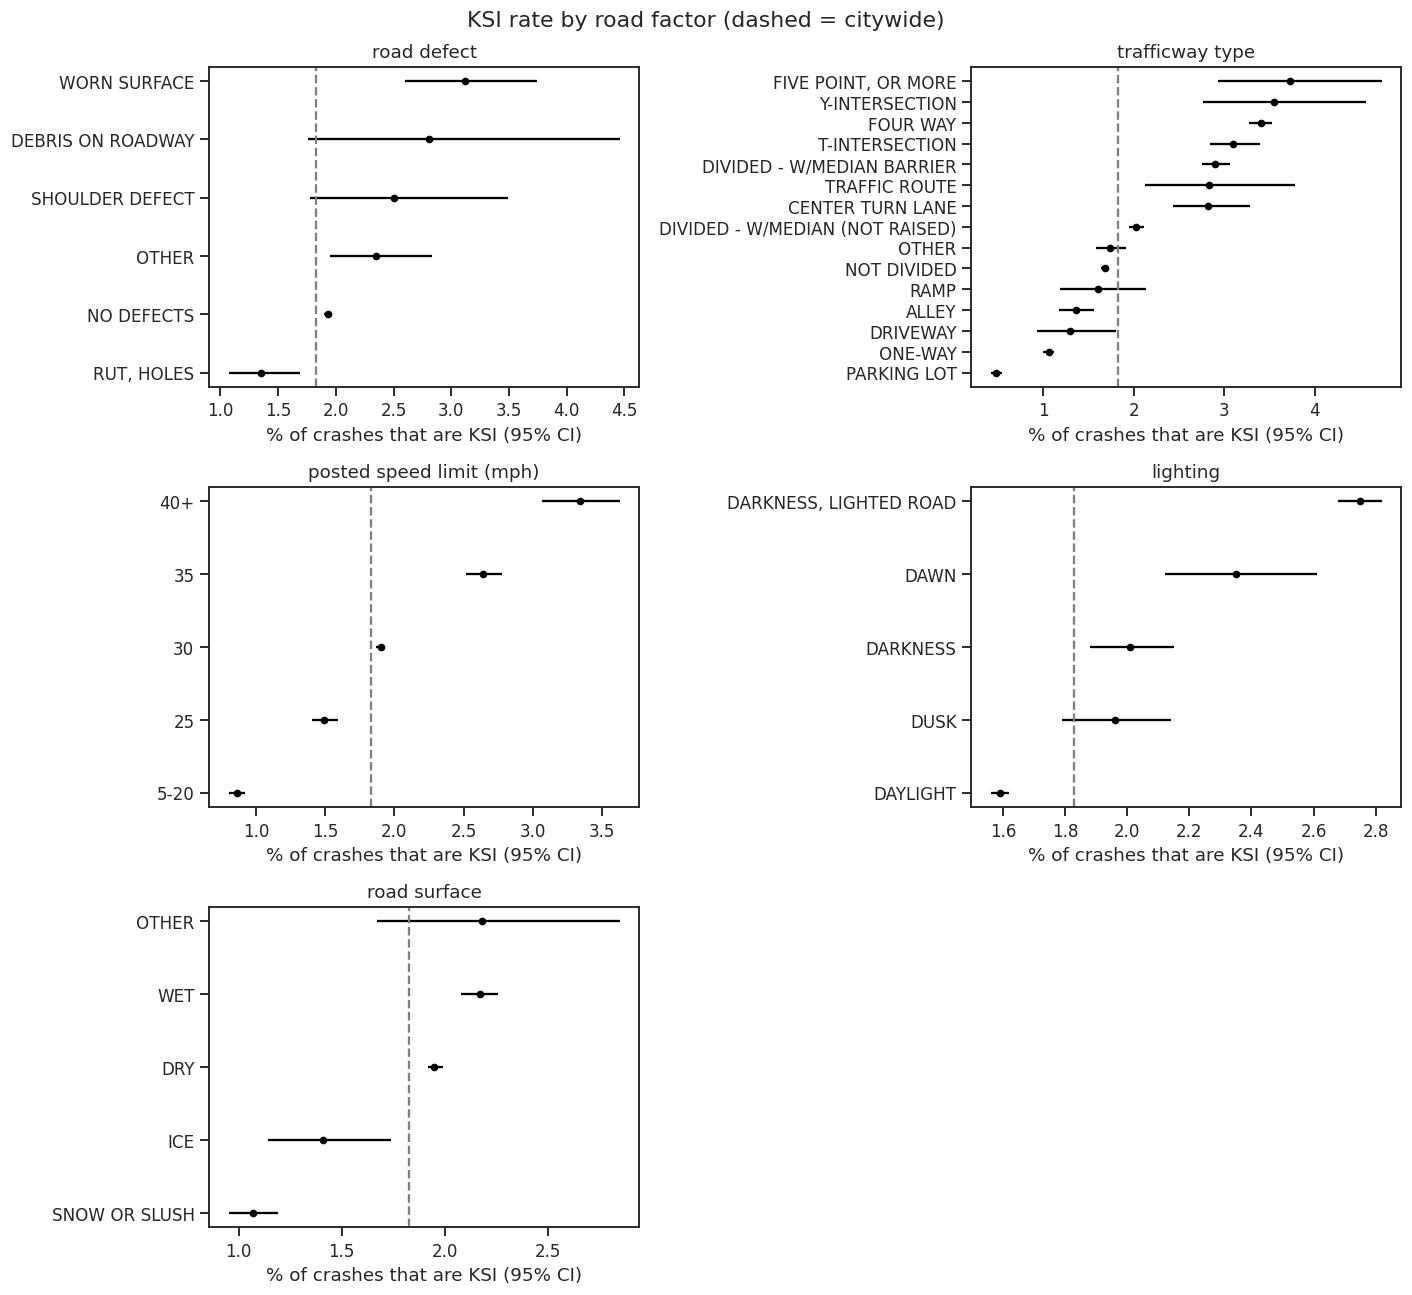

In [20]:
panels = {"ROAD_DEFECT": "road defect", "TRAFFICWAY_TYPE": "trafficway type", "speed_cat": "posted speed limit (mph)", "LIGHTING_CONDITION": "lighting", "ROADWAY_SURFACE_COND": "road surface"}
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, (col, title) in zip(axes.flat, panels.items()):
    rates = wilson_rates(crashes, col).sort_values("rate_pct")
    ax.errorbar(rates["rate_pct"], rates.index.astype(str), xerr=[rates["rate_pct"] - rates["lo"], rates["hi"] - rates["rate_pct"]], fmt="o", color="black", ms=4)
    ax.axvline(city_ksi, ls="--", color="grey")
    ax.set(title=title, xlabel="% of crashes that are KSI (95% CI)")
axes.flat[-1].axis("off")
fig.suptitle("KSI rate by road factor (dashed = citywide)")
fig.tight_layout()

**Verified findings from saved outputs:** The crash-level KSI rate rises across posted-speed categories: 0.86% at 5–20 mph (818/94,915), 1.90% at 30 mph (12,259/645,877), and 3.34% at 40+ mph (521/15,607). These are associations conditional on a reported crash, not evidence of the causal effect of changing a speed limit. Four-way intersections show 3.40% KSI (2,604/76,613); five-point intersections show 3.73% (64/1,715). Worn-surface crashes show 3.12% KSI (111/3,559), but road-defect fields are missing for 20.4% of crashes and may be recorded differently by severity.


### Crash type and primary cause

In [21]:
display(wilson_rates(crashes, "FIRST_CRASH_TYPE"))
display(wilson_rates(crashes, "PRIM_CONTRIBUTORY_CAUSE", min_n=1000).head(12))

,n,events,rate_pct,lo,hi
FIRST_CRASH_TYPE,,,,,
PEDESTRIAN,22041,3791,17.20,16.71,17.70
PEDALCYCLIST,15094,1374,9.10,8.65,9.57
OVERTURNED,532,44,8.27,6.22,10.92
HEAD ON,7299,451,6.18,5.65,6.75
FIXED OBJECT,41403,1537,3.71,3.53,3.90
OTHER NONCOLLISION,2388,87,3.64,2.96,4.47
OTHER OBJECT,8943,257,2.87,2.55,3.24
ANIMAL,677,19,2.81,1.80,4.34
ANGLE,96009,2457,2.56,2.46,2.66


,n,events,rate_pct,lo,hi
PRIM_CONTRIBUTORY_CAUSE,,,,,
PHYSICAL CONDITION OF DRIVER,5282,551,10.43,9.64,11.28
EXCEEDING AUTHORIZED SPEED LIMIT,1031,81,7.86,6.37,9.66
UNDER THE INFLUENCE OF ALCOHOL/DRUGS (USE WHEN ARREST IS EFFECTED),4246,255,6.01,5.33,6.76
DISREGARDING TRAFFIC SIGNALS,18011,1074,5.96,5.63,6.32
DISREGARDING OTHER TRAFFIC SIGNS,1867,93,4.98,4.08,6.06
DRIVING ON WRONG SIDE/WRONG WAY,5066,245,4.84,4.28,5.46
"OPERATING VEHICLE IN ERRATIC, RECKLESS, CARELESS, NEGLIGENT OR AGGRESSIVE MANNER",10978,476,4.34,3.97,4.73
"VISION OBSCURED (SIGNS, TREE LIMBS, BUILDINGS, ETC.)",5052,209,4.14,3.62,4.72
DISREGARDING STOP SIGN,9268,336,3.63,3.26,4.03


**Verified findings from saved outputs:** The crash-type and cause tables identify particularly severe pedestrian/cyclist crashes and head-on collisions. Crash type and reported contributing cause are recorded after a crash; adjusted associations may reflect injury mechanisms and reporting, not independently manipulable risk factors. Compare both counts and rates before allocating resources.


### Crash-level adjusted model for KSI

The descriptive rates compare one characteristic at a time. The following multivariable logistic model estimates **conditional associations** between recorded crash characteristics and KSI. Crash type and recorded primary cause may reflect post-crash coding; interpret them as descriptive correlates, not pre-crash causal risk factors. Sparse categories are collapsed to improve stability.

In [22]:
ksi_data = crashes.dropna(subset=["ksi"]).copy()
for col, min_count in {"ROAD_DEFECT": 1500, "TRAFFICWAY_TYPE": 1500, "LIGHTING_CONDITION": 1500, "ROADWAY_SURFACE_COND": 1500, "TRAFFIC_CONTROL_DEVICE": 1500, "FIRST_CRASH_TYPE": 1500, "PRIM_CONTRIBUTORY_CAUSE": 5000, "speed_cat": 1}.items():
    ksi_data[col] = collapse_rare(ksi_data[col], min_count)
print(f"model rows: {len(ksi_data):,}")

refs = {col: most_common(ksi_data[col]) for col in ["ROAD_DEFECT", "TRAFFICWAY_TYPE", "LIGHTING_CONDITION", "ROADWAY_SURFACE_COND", "TRAFFIC_CONTROL_DEVICE", "FIRST_CRASH_TYPE", "PRIM_CONTRIBUTORY_CAUSE"]}
refs = {"speed_cat": "30", **refs}
print("reference levels:", refs)

ksi_fit = smf.logit(treatment_formula("ksi", refs), data=ksi_data).fit(disp=0)
ksi_or = odds_ratios(ksi_fit)
del ksi_data, ksi_fit
ksi_or[~ksi_or.index.str.contains("UNKNOWN|Other|FIRST_CRASH|PRIM_")]

model rows: 875,925
reference levels: {'speed_cat': '30', 'ROAD_DEFECT': 'NO DEFECTS', 'TRAFFICWAY_TYPE': 'NOT DIVIDED', 'LIGHTING_CONDITION': 'DAYLIGHT', 'ROADWAY_SURFACE_COND': 'DRY', 'TRAFFIC_CONTROL_DEVICE': 'NO CONTROLS', 'FIRST_CRASH_TYPE': 'PARKED MOTOR VEHICLE', 'PRIM_CONTRIBUTORY_CAUSE': 'FAILING TO YIELD RIGHT-OF-WAY'}


,OR,lo,hi,p
speed_cat: 25,0.87,0.81,0.94,1.533136e-04
speed_cat: 35,1.32,1.25,1.40,2.851343e-22
speed_cat: 40+,1.72,1.55,1.90,4.585444e-25
speed_cat: 5-20,0.70,0.64,0.76,3.584511e-18
ROAD_DEFECT: OTHER,1.05,0.86,1.29,6.342020e-01
"ROAD_DEFECT: RUT, HOLES",0.38,0.30,0.49,1.852075e-14
ROAD_DEFECT: WORN SURFACE,1.31,1.08,1.60,7.110115e-03
TRAFFICWAY_TYPE: ALLEY,0.59,0.51,0.69,1.975674e-11
TRAFFICWAY_TYPE: CENTER TURN LANE,1.28,1.08,1.50,3.527760e-03
TRAFFICWAY_TYPE: DIVIDED - W/MEDIAN (NOT RAISED),1.13,1.07,1.18,8.280565e-07


In [23]:
ksi_or[ksi_or.index.str.contains("FIRST_CRASH|PRIM_") & ~ksi_or.index.str.contains("UNKNOWN|Other")].sort_values("OR", ascending=False)

,OR,lo,hi,p
FIRST_CRASH_TYPE: PEDESTRIAN,30.83,28.62,33.21,0.000000e+00
FIRST_CRASH_TYPE: PEDALCYCLIST,14.47,13.28,15.76,0.000000e+00
FIRST_CRASH_TYPE: HEAD ON,7.50,6.66,8.45,1.761166e-240
PRIM_CONTRIBUTORY_CAUSE: PHYSICAL CONDITION OF DRIVER,6.68,6.00,7.43,5.690637e-267
FIRST_CRASH_TYPE: OTHER NONCOLLISION,5.91,4.68,7.47,1.752020e-50
FIRST_CRASH_TYPE: FIXED OBJECT,4.74,4.36,5.14,4.746432e-298
FIRST_CRASH_TYPE: OTHER OBJECT,4.47,3.88,5.15,7.175148e-95
FIRST_CRASH_TYPE: ANGLE,3.39,3.12,3.67,1.021505e-190
FIRST_CRASH_TYPE: TURNING,2.53,2.33,2.74,7.915280e-114
FIRST_CRASH_TYPE: REAR TO SIDE,2.06,1.53,2.76,1.430421e-06


**Verified findings from saved outputs:** The crash-level model contains 875,925 rows. Compared with its selected reference categories, pedestrian first-crash type has OR 30.83 (95% CI 28.62–33.21), pedalcyclist OR 14.47 (13.28–15.76), and head-on OR 7.50 (6.66–8.45). These describe the odds of a crash having a fatal/incapacitating injury, not risk per roadway user. Report the reference levels from the model code and do not interpret post-crash classifications causally.


### Q1.1a — Vehicles involved in injury crashes

**Important:** `injury` below is a **crash-level** flag merged onto vehicle units. It means the unit was **involved in an injury crash**, *not* that this unit's occupant was injured. The vehicle model is exploratory and should be interpreted accordingly.

In [24]:
wilson_rates(vehicles, "UNIT_TYPE", "injury", min_n=300)

,n,events,rate_pct,lo,hi
UNIT_TYPE,,,,,
PEDESTRIAN,24224,21338,88.09,87.67,88.49
BICYCLE,15520,11119,71.64,70.93,72.35
NON-MOTOR VEHICLE,1687,510,30.23,28.09,32.47
NON-CONTACT VEHICLE,300,81,27.00,22.29,32.29
DRIVER,1494890,230460,15.42,15.36,15.47
DRIVERLESS,11922,1113,9.34,8.83,9.87
PARKED,238311,18290,7.67,7.57,7.78


In [25]:
drivers = vehicles.query("UNIT_TYPE == 'DRIVER'").copy()
detail_cols = ["VEHICLE_TYPE", "VEHICLE_USE", "MANEUVER"]
drivers[detail_cols] = drivers[detail_cols].mask(drivers[detail_cols].isin(["UNKNOWN/NA", "OTHER"]))
model_year = pd.to_numeric(drivers["VEHICLE_YEAR"], errors="coerce")
vehicle_age = (drivers["year"] - model_year).where(model_year.between(1970, drivers["year"] + 1))
drivers["veh_age_cat"] = pd.cut(vehicle_age, [-np.inf, 5, 10, 15, np.inf], labels=["0-5", "6-10", "11-15", "16+"])
print(f"driver units: {len(drivers):,}")
display(wilson_rates(drivers, "VEHICLE_TYPE", "injury").head(12))
display(wilson_rates(drivers, "MANEUVER", "injury").head(12))

driver units: 1,494,890


,n,events,rate_pct,lo,hi
VEHICLE_TYPE,,,,,
MOPED OR MOTORIZED BICYCLE,738,478,64.77,61.25,68.13
MOTORCYCLE (OVER 150CC),3855,2443,63.37,61.84,64.88
PASSENGER,913491,154034,16.86,16.79,16.94
SPORT UTILITY VEHICLE (SUV),215625,33836,15.69,15.54,15.85
VAN/MINI-VAN,65466,10130,15.47,15.20,15.75
PICKUP,51084,7455,14.59,14.29,14.90
BUS OVER 15 PASS.,19850,2550,12.85,12.39,13.32
TRACTOR W/O SEMI-TRAILER,1920,220,11.46,10.11,12.96
OTHER VEHICLE WITH TRAILER,1930,193,10.00,8.74,11.42


,n,events,rate_pct,lo,hi
MANEUVER,,,,,
TURNING ON RED,683,197,28.84,25.57,32.35
DRIVING WRONG WAY,2748,726,26.42,24.80,28.10
TURNING LEFT,107262,25189,23.48,23.23,23.74
SKIDDING/CONTROL LOSS,6212,1419,22.84,21.82,23.90
AVOIDING VEHICLES/OBJECTS,7214,1398,19.38,18.48,20.31
NEGOTIATING A CURVE,1922,368,19.15,17.45,20.97
SLOW/STOP - LEFT TURN,1604,307,19.14,17.29,21.14
U-TURN,10314,1954,18.95,18.20,19.71
STRAIGHT AHEAD,814880,144182,17.69,17.61,17.78


In [26]:
display(wilson_rates(drivers, "VEHICLE_USE", "injury").head(10))
display(wilson_rates(drivers, "veh_age_cat", "injury"))

,n,events,rate_pct,lo,hi
VEHICLE_USE,,,,,
RIDESHARE SERVICE,14595,3247,22.25,21.58,22.93
POLICE,10197,1981,19.43,18.67,20.21
PERSONAL,995037,172261,17.31,17.24,17.39
CTA,14048,2256,16.06,15.46,16.68
TAXI/FOR HIRE,14659,2079,14.18,13.63,14.76
TOW TRUCK,3254,458,14.07,12.92,15.31
OTHER TRANSIT,1765,233,13.20,11.70,14.86
LAWN CARE/LANDSCAPING,533,69,12.95,10.36,16.06
NOT IN USE,5836,750,12.85,12.02,13.73


,n,events,rate_pct,lo,hi
veh_age_cat,,,,,
16+,195400,35404,18.12,17.95,18.29
11-15,255531,44605,17.46,17.31,17.60
6-10,335015,54521,16.27,16.15,16.40
0-5,447291,68600,15.34,15.23,15.44


In [27]:
veh_data = drivers.dropna(subset=["injury"]).copy()
for col in ["VEHICLE_TYPE", "VEHICLE_USE", "MANEUVER"]:
    veh_data[col] = collapse_rare(veh_data[col], 3000)
veh_data["veh_age_cat"] = collapse_rare(veh_data["veh_age_cat"])

veh_refs = {"VEHICLE_TYPE": most_common(veh_data["VEHICLE_TYPE"]), "MANEUVER": most_common(veh_data["MANEUVER"]), "VEHICLE_USE": most_common(veh_data["VEHICLE_USE"]), "veh_age_cat": "0-5"}
print("reference levels:", veh_refs)
inj_or = odds_ratios(smf.logit(treatment_formula("injury", veh_refs), data=veh_data).fit(disp=0))
del veh_data, drivers
inj_or[~inj_or.index.str.contains("UNKNOWN|Other")].sort_values("OR", ascending=False)

reference levels: {'VEHICLE_TYPE': 'PASSENGER', 'MANEUVER': 'STRAIGHT AHEAD', 'VEHICLE_USE': 'PERSONAL', 'veh_age_cat': '0-5'}


,OR,lo,hi,p
VEHICLE_TYPE: MOTORCYCLE (OVER 150CC),8.63,8.08,9.23,0.000000e+00
VEHICLE_USE: CTA,1.70,1.55,1.86,6.691224e-30
VEHICLE_USE: POLICE,1.49,1.41,1.56,3.463414e-53
VEHICLE_USE: RIDESHARE SERVICE,1.49,1.43,1.55,3.346048e-86
MANEUVER: TURNING LEFT,1.44,1.42,1.47,0.000000e+00
MANEUVER: SKIDDING/CONTROL LOSS,1.28,1.21,1.36,4.842214e-16
veh_age_cat: 16+,1.24,1.22,1.26,3.796793e-188
VEHICLE_USE: TOW TRUCK,1.17,1.06,1.30,2.026459e-03
veh_age_cat: 11-15,1.17,1.16,1.19,6.576883e-122
MANEUVER: U-TURN,1.11,1.05,1.16,6.048613e-05


**Verified findings from saved outputs:** Driver units total 1,494,890. Motorcycle units (3,855) were involved in injury crashes at 63.37%, compared with passenger-vehicle units (913,491) at 16.86%. This is a *unit-involved-in-an-injury-crash* outcome, not an occupant injury outcome. Multiple units from one crash share the same outcome, so naïve unit-level regression standard errors can be too narrow. Motorcycle exposure and vehicle mix are not controlled.


### Q1.1b Worse injuries for people (person table)

Each person has an `INJURY_CLASSIFICATION`. It's ordered from no indication of injury, to reported but not evident, nonincapacitating, incapacitating, and fatal. That's an ordinal outcome, so I use a proportional odds (ordinal logistic) model, statsmodels `OrderedModel`, like the ordinal model in the NHANES notes. Safety equipment gets grouped into used, not used or improper, none present (mostly pedestrians and cyclists), and unknown.

In [28]:
safety_raw = people["SAFETY_EQUIPMENT"]
airbag_raw = people["AIRBAG_DEPLOYED"].fillna("")
age = pd.to_numeric(people["AGE"], errors="coerce")
person_counts = people["PERSON_TYPE"].value_counts()

people = people.assign(
    severity=people["INJURY_CLASSIFICATION"].astype(SEVERITY),
    person_type=people["PERSON_TYPE"].where(people["PERSON_TYPE"].isin(person_counts.index[person_counts >= 5000]), "Other"),
    age_cat=pd.cut(age.where(age.between(0, 100)), [-np.inf, 15, 24, 44, 64, np.inf], labels=["0-15", "16-24", "25-44", "45-64", "65+"]),
    sex=people["SEX"].where(people["SEX"].isin(["M", "F"])),
    safety=np.select([safety_raw.isna() | safety_raw.isin(["USAGE UNKNOWN", "NOT APPLICABLE", "UNKNOWN", "OTHER", "CHILD RESTRAINT NOT STATED"]), safety_raw.str.contains("NOT USED|IMPROPERLY|NOT DOT", na=False), safety_raw.eq("NONE PRESENT"), safety_raw.isin(["WHEELCHAIR", "STRETCHER"])], [None, "not used/improper", "none present", None], default=None),
    impaired=people["PHYSICAL_CONDITION"].str.contains("IMPAIRED|DRINKING", na=False),
    driver_action=people["DRIVER_ACTION"].mask(people["DRIVER_ACTION"].eq("UNKNOWN")),
    airbag=np.select([airbag_raw.str.startswith("DEPLOYED"), airbag_raw.eq("DID NOT DEPLOY"), airbag_raw.eq("NOT APPLICABLE")], ["deployed", "did not deploy", "not applicable"], default=None),
    ejected=people["EJECTION"].map({"TOTALLY EJECTED": "ejected", "PARTIALLY EJECTED": "ejected", "TRAPPED/EXTRICATED": "trapped", "NONE": "none"}),
)
people["ksi"] = people["severity"].isin(["INCAPACITATING INJURY", "FATAL"]).astype(float).where(people["severity"].notna())
del safety_raw, airbag_raw, age

people["INJURY_CLASSIFICATION"].value_counts(dropna=False).to_frame("n").assign(pct=lambda t: (100 * t["n"] / len(people)).round(3))
print('Safety-equipment raw values (check coding before interpreting):')
display(people['SAFETY_EQUIPMENT'].value_counts(dropna=False).head(25))


Safety-equipment raw values (check coding before interpreting):


,count
SAFETY_EQUIPMENT,
USAGE UNKNOWN,962351
SAFETY BELT USED,843084
NONE PRESENT,67613
HELMET NOT USED,11717
SAFETY BELT NOT USED,9953
CHILD RESTRAINT - FORWARD FACING,6008
NaN,5443
BICYCLE HELMET (PEDACYCLIST INVOLVED ONLY),4801
CHILD RESTRAINT USED,4343


In [29]:
display(wilson_rates(people, "person_type", min_n=1000))
display(wilson_rates(people, "age_cat"))
display(wilson_rates(people, "sex"))

,n,events,rate_pct,lo,hi
person_type,,,,,
PEDESTRIAN,24224,4143,17.10,16.63,17.58
BICYCLE,15518,1389,8.95,8.51,9.41
Other,1777,63,3.55,2.78,4.51
PASSENGER,390686,4044,1.04,1.00,1.07
DRIVER,1494890,9223,0.62,0.60,0.63


,n,events,rate_pct,lo,hi
age_cat,,,,,
65+,104978,1655,1.58,1.50,1.65
16-24,227187,3184,1.40,1.35,1.45
0-15,78524,1068,1.36,1.28,1.44
45-64,351286,4371,1.24,1.21,1.28
25-44,609243,7127,1.17,1.14,1.20


,n,events,rate_pct,lo,hi
sex,,,,,
M,996433,10755,1.08,1.06,1.1
F,719173,7713,1.07,1.05,1.1


In [30]:
occupants = people[people["PERSON_TYPE"].isin(["DRIVER", "PASSENGER"])]
display(wilson_rates(occupants, "safety"))
display(wilson_rates(occupants, "ejected"))
display(wilson_rates(people.query("PERSON_TYPE == 'DRIVER'"), "impaired"))

,n,events,rate_pct,lo,hi
safety,,,,,
not used/improper,13892,941,6.77,6.37,7.20
none present,50899,566,1.11,1.02,1.21


,n,events,rate_pct,lo,hi
ejected,,,,,
ejected,3097,700,22.60,21.16,24.11
trapped,1063,230,21.64,19.27,24.21
none,1755024,11206,0.64,0.63,0.65


,n,events,rate_pct,lo,hi
impaired,,,,,
True,8071,235,2.91,2.57,3.30
False,1486819,8988,0.60,0.59,0.62


Three more columns looked useful at first. Driver action covers most drivers. The cell phone flag (People) and the exceeded speed limit flag (Vehicles) are almost always blank, so I check how many rows they actually have before using them.

In [31]:
display(wilson_rates(people.query("PERSON_TYPE == 'DRIVER'"), "driver_action", min_n=1000))
display(wilson_rates(occupants, "airbag"))
display(people.groupby("CELL_PHONE_USE", dropna=False)["ksi"].agg(n="size", ksi_pct=lambda x: round(100 * x.mean(), 2)))
display(vehicles.query("UNIT_TYPE == 'DRIVER'").groupby("EXCEED_SPEED_LIMIT_I", dropna=False).agg(n=("injury", "size"), injury_pct=("injury", lambda x: round(100 * x.mean(), 2)), ksi_pct=("ksi", lambda x: round(100 * x.mean(), 2))))
del vehicles, occupants

,n,events,rate_pct,lo,hi
driver_action,,,,,
WRONG WAY/SIDE,6066,147,2.42,2.07,2.84
EMERGENCY VEHICLE ON CALL,1503,30,2.00,1.40,2.84
TOO FAST FOR CONDITIONS,21323,419,1.97,1.79,2.16
DISREGARDED CONTROL DEVICES,27467,413,1.50,1.37,1.65
EVADING POLICE VEHICLE,2308,29,1.26,0.88,1.80
OVERCORRECTED,3813,36,0.94,0.68,1.30
OTHER,140233,1307,0.93,0.88,0.98
CELL PHONE USE OTHER THAN TEXTING,1959,14,0.71,0.43,1.20
NONE,514349,3172,0.62,0.60,0.64


,n,events,rate_pct,lo,hi
airbag,,,,,
deployed,139042,6436,4.63,4.52,4.74
not applicable,479245,2578,0.54,0.52,0.56
did not deploy,878666,3224,0.37,0.35,0.38


,n,ksi_pct
CELL_PHONE_USE,,
N,239,2.93
Y,375,2.93
NaN,1927037,0.98


,n,injury_pct,ksi_pct
EXCEED_SPEED_LIMIT_I,,,
N,359,34.26,6.96
Y,998,39.28,10.02
NaN,1493533,15.40,1.71


**Interpretation:** Raw driver-action, impairment and phone-use associations are exploratory. Missing or blank fields and after-crash police recording can bias comparisons. The subsequent model uses person type, age, sex, posted-speed category and lighting; it does **not** include driver action.


In [32]:
# A person-level binary KSI model is more directly aligned with the client's severe-injury question
# than a very large proportional-odds model. Driver-only fields are not included for pedestrians.
# Safety equipment is omitted from the all-person model because its meaning differs by person type.
model_cols = ['ksi', 'person_type', 'age_cat', 'sex', 'speed_cat', 'LIGHTING_CONDITION']
person_model = people[model_cols].dropna().copy()
for col in ['person_type', 'LIGHTING_CONDITION']:
    person_model[col] = collapse_rare(person_model[col], 3000)
for col in ['age_cat', 'sex', 'speed_cat']:
    person_model[col] = person_model[col].astype(str)
    person_model = person_model.loc[person_model[col].ne('nan')]
print('Person-level model sample:', len(person_model), 'KSI:', int(person_model.ksi.sum()))

person_refs = {'person_type': 'DRIVER', 'age_cat': '25-44', 'sex': 'F', 'speed_cat': '30',
               'LIGHTING_CONDITION': most_common(person_model['LIGHTING_CONDITION'])}
for factor, ref in person_refs.items():
    assert ref in person_model[factor].astype(str).unique(), f'Missing model reference {factor}={ref}'
assert len(person_model) >= 10000 and person_model['ksi'].sum() >= 100, 'Model sample too small'
print(f'Complete-case retention: {len(person_model)/len(people):.1%}; exclusions may be nonrandom.')
person_formula = treatment_formula('ksi', person_refs)
person_fit = smf.glm(person_formula, data=person_model, family=__import__('statsmodels.api',fromlist=['families']).families.Binomial()).fit()
person_or = odds_ratios(person_fit)
display(person_or.loc[~person_or.index.str.contains('UNKNOWN|Other')].sort_values('OR', ascending=False))
print('Interpretation: adjusted associations, not causal effects; speed limit is a road proxy.')


Person-level model sample: 1323898 KSI: 17065
Complete-case retention: 68.7%; exclusions may be nonrandom.


,OR,lo,hi,p
person_type: PEDESTRIAN,27.14,26.02,28.31,0.000000e+00
person_type: BICYCLE,15.07,14.16,16.04,0.000000e+00
speed_cat: 40+,2.11,1.94,2.29,1.285661e-69
person_type: PASSENGER,1.86,1.78,1.94,4.057089e-175
"LIGHTING_CONDITION: DARKNESS, LIGHTED ROAD",1.85,1.79,1.91,1.362669e-271
LIGHTING_CONDITION: DAWN,1.57,1.41,1.75,2.620973e-16
LIGHTING_CONDITION: DARKNESS,1.40,1.30,1.51,2.518242e-19
speed_cat: 35,1.38,1.31,1.46,5.042735e-32
age_cat: 65+,1.37,1.29,1.45,4.432833e-27
LIGHTING_CONDITION: DUSK,1.13,1.03,1.24,1.151665e-02


Interpretation: adjusted associations, not causal effects; speed limit is a road proxy.


In [33]:
# Compare included vs excluded people; selection into the complete-case model is not random by default.
model_included = people.index.isin(person_model.index)
check = pd.DataFrame({'included': model_included, 'ksi': people['ksi'], 'person_type': people['person_type']})
print('Model inclusion fraction:', round(model_included.mean(), 3))
print('KSI rate by inclusion status:')
display(check.groupby('included')['ksi'].agg(['count','mean','sum']))
print('Person-type composition by inclusion status (%):')
display((100*pd.crosstab(check['person_type'], check['included'], normalize='columns')).round(1))


Model inclusion fraction: 0.687
KSI rate by inclusion status:


,count,mean,sum
included,,,
False,603197,0.002979,1797.0
True,1323898,0.012890,17065.0


Person-type composition by inclusion status (%):


included,False,True
person_type,,
BICYCLE,0.4,1.0
DRIVER,72.4,79.9
Other,0.2,0.1
PASSENGER,26.5,17.5
PEDESTRIAN,0.4,1.6


### Model choice and diagnostics

**Why binomial GLM instead of the original 500k-row ordinal model?** The client's primary endpoint is killed/seriously injured (KSI). Binary logistic regression directly estimates adjusted odds for that endpoint, is easier to explain to CDOT, and avoids proportional-odds assumptions. The ordinal model can be a sensitivity analysis, but is not necessary for the main deliverable. Check the event count, confidence intervals, and category sizes; odds ratios are not risk ratios.

,n,observed_rate,predicted_rate
decile,,,
0,132390,0.004781,0.004764
1,132390,0.006005,0.006208
2,132390,0.005793,0.006339
3,132389,0.006791,0.006669
4,132390,0.006496,0.007047
5,132390,0.007508,0.008365
6,132389,0.010250,0.010091
7,132390,0.013060,0.011698
8,132390,0.012886,0.013343


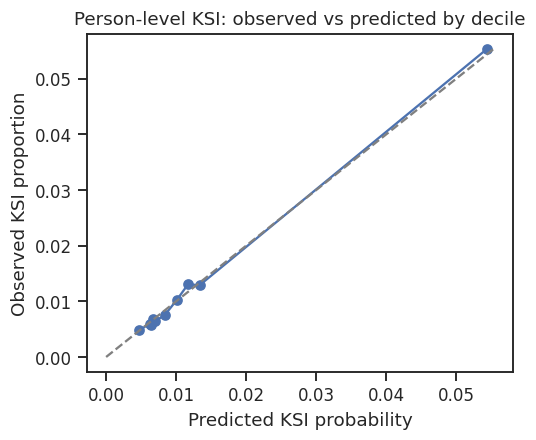

In [34]:
# Check how well predicted KSI probabilities track observed outcomes across risk deciles.
pred = person_fit.predict(person_model)
deciles = pd.qcut(pred.rank(method='first'), 10, labels=False)
calibration = pd.DataFrame({'observed':person_model['ksi'].to_numpy(), 'predicted':pred.to_numpy(), 'decile':deciles.to_numpy()}).groupby('decile').agg(n=('observed','size'), observed_rate=('observed','mean'), predicted_rate=('predicted','mean'))
display(calibration)
ax = calibration.plot(x='predicted_rate', y='observed_rate', marker='o', legend=False, figsize=(5,4), title='Person-level KSI: observed vs predicted by decile')
ax.plot([0,calibration[['observed_rate','predicted_rate']].max().max()], [0,calibration[['observed_rate','predicted_rate']].max().max()], '--', color='gray')
ax.set(xlabel='Predicted KSI probability',ylabel='Observed KSI proportion'); plt.show()


**Model diagnostic interpretation.** The decile calibration plot is **in-sample**, so apparent agreement does not demonstrate out-of-sample predictive validity. Use the new held-out evaluation below. Odds ratios for pedestrians/cyclists compare **people involved in reported crashes**, not risk per trip or per mile. The very large sample makes small effects statistically significant; assess magnitude, uncertainty and practical importance. People within the same crash may be correlated; the model’s default standard errors do not account for crash clustering.


In [35]:
# Held-out assessment with a CRASH-LEVEL split to avoid putting people from the same crash in both sets.
# Runs an additional model, potentially taking several minutes.
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
model_eval = people.loc[person_model.index, ['CRASH_RECORD_ID']].join(person_model)
split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_SEED)
train_idx, test_idx = next(split.split(model_eval, groups=model_eval['CRASH_RECORD_ID']))
train, test = model_eval.iloc[train_idx], model_eval.iloc[test_idx]
# Fix factor levels from the full model to keep design matrices compatible in train/test.
for col in person_refs:
    levels = person_model[col].astype('category').cat.categories
    train[col] = pd.Categorical(train[col], categories=levels)
    test[col] = pd.Categorical(test[col], categories=levels)
heldout_fit = smf.glm(person_formula, data=train, family=__import__('statsmodels.api',fromlist=['families']).families.Binomial()).fit()
p_test = heldout_fit.predict(test)
print('Held-out people:', len(test), 'KSI cases:', int(test.ksi.sum()))
print('ROC AUC:', round(roc_auc_score(test.ksi, p_test), 3))
print('Average precision:', round(average_precision_score(test.ksi, p_test), 3))
print('KSI prevalence:', round(test.ksi.mean(), 4))
print('Brier score:', round(brier_score_loss(test.ksi, p_test), 5))


/tmp/ipykernel_7276/3490111549.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train[col] = pd.Categorical(train[col], categories=levels)
/tmp/ipykernel_7276/3490111549.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test[col] = pd.Categorical(test[col], categories=levels)
/tmp/ipykernel_7276/3490111549.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: htt

Held-out people: 264995 KSI cases: 3586
ROC AUC: 0.733
Average precision: 0.092
KSI prevalence: 0.0135
Brier score: 0.01273


**Verified findings from saved outputs:** The person-level model includes 1,323,898 complete cases and 17,065 KSI cases (1.29%). Adjusted ORs versus drivers: pedestrians 27.14 (95% CI 26.02–28.31), cyclists 15.07 (14.16–16.04), passengers 1.86 (1.78–1.94). Roads posted 40+ mph have OR 2.11 (1.94–2.29) versus 30 mph. In-sample calibration is close at the decile level, but it does not establish out-of-sample accuracy. The complete-case sample omits ~31.3% of person records; investigate missingness and potential selection bias.


### Safety equipment: targeted descriptive analysis

Airbag deployment and ejection reflect crash forces and are not independent causal preventive exposures. `PERSON_TYPE == DRIVER/PASSENGER` includes motorcycle occupants; helmet and seat-belt records should **not** be interpreted as interchangeable or directly compared without stratifying by vehicle type. Missing or unknown use is common. All comparisons below are descriptive, subject to recording bias and crash severity confounding.


In [36]:
# Safety-equipment categories must be audited against raw values before interpreting.
# Belt comparison among drivers/passengers only; avoid combining helmet and belt use.
occ = people[people['PERSON_TYPE'].isin(['DRIVER','PASSENGER'])].copy()
print('Observed KSI rates by recorded safety equipment (occupants):')
display(wilson_rates(occ, 'SAFETY_EQUIPMENT', min_n=500).head(20))
print('Airbag categories (descriptive only):')
display(wilson_rates(occ, 'airbag', min_n=500))
print('Ejection categories (descriptive only):')
display(wilson_rates(occ, 'ejected', min_n=500))


Observed KSI rates by recorded safety equipment (occupants):


,n,events,rate_pct,lo,hi
SAFETY_EQUIPMENT,,,,,
HELMET NOT USED,2450,472,19.27,17.75,20.87
DOT COMPLIANT MOTORCYCLE HELMET,1905,296,15.54,13.98,17.23
SAFETY BELT NOT USED,9762,385,3.94,3.58,4.35
CHILD RESTRAINT NOT USED,774,14,1.81,1.08,3.01
NONE PRESENT,50899,566,1.11,1.02,1.21
USAGE UNKNOWN,957687,6496,0.68,0.66,0.69
SAFETY BELT USED,842783,4852,0.58,0.56,0.59
BOOSTER SEAT,1607,7,0.44,0.21,0.90
CHILD RESTRAINT - TYPE UNKNOWN,3219,13,0.40,0.24,0.69


Airbag categories (descriptive only):


,n,events,rate_pct,lo,hi
airbag,,,,,
deployed,139042,6436,4.63,4.52,4.74
not applicable,479245,2578,0.54,0.52,0.56
did not deploy,878666,3224,0.37,0.35,0.38


Ejection categories (descriptive only):


,n,events,rate_pct,lo,hi
ejected,,,,,
ejected,3097,700,22.60,21.16,24.11
trapped,1063,230,21.64,19.27,24.21
none,1755024,11206,0.64,0.63,0.65


**Interpretation:** Among reported occupants, recorded seat-belt nonuse shows 3.94% KSI (385/9,762), versus 0.58% (4,852/842,783) with recorded belt use. These categories are observational, may mix vehicle types and are vulnerable to differential documentation. Airbag deployment and ejection occur during the crash and are strong severity indicators, **not evidence that deploying airbags causes injuries**. Avoid causal claims or policy effects from these comparisons.


## Q2. Where and when do crashes happen?

### Q2.1 Time of year, day of week, time of day

Raw monthly totals are a bit unfair to February, so for month and weekday I use crashes per day (total crashes divided by the number of calendar days in that group). I report KSI counts next to the KSI rate, because a busy time with a normal rate can still produce the most KSI crashes.

In [37]:
calendar = pd.DataFrame({"day": pd.date_range("2018-01-01", "2025-12-31", freq="D")})
calendar = calendar.assign(month=calendar["day"].dt.strftime("%b").astype(MONTH), dow=calendar["day"].dt.strftime("%a").astype(DOW))


def per_day(by):
    """Crashes and KSI crashes per calendar day in each group."""
    out = crashes.groupby(by, observed=True)["ksi"].agg(crashes="size", ksi_pct="mean", ksi="sum")
    n_days = calendar[by].value_counts()
    return out.assign(ksi_pct=(100 * out["ksi_pct"]).round(2), ksi=out["ksi"].astype(int), n_days=n_days, crashes_per_day=(out["crashes"] / n_days).round(1), ksi_per_100_days=(100 * out["ksi"] / n_days).round(1))


by_month = per_day("month")
by_dow = per_day("dow")
display(by_month)
display(by_dow)

,crashes,ksi_pct,ksi,n_days,crashes_per_day,ksi_per_100_days
month,,,,,,
Jan,67160,1.60,1074,248,270.8,433.1
Feb,66399,1.51,999,226,293.8,442.0
Mar,68531,1.71,1172,248,276.3,472.6
Apr,67412,1.73,1160,240,280.9,483.3
May,78434,1.90,1488,248,316.3,600.0
Jun,78753,1.99,1562,240,328.1,650.8
Jul,78311,2.12,1657,248,315.8,668.1
Aug,78429,2.03,1587,248,316.2,639.9
Sep,76006,1.96,1488,240,316.7,620.0


,crashes,ksi_pct,ksi,n_days,crashes_per_day,ksi_per_100_days
dow,,,,,,
Sun,110643,2.19,2419,417,265.3,580.1
Mon,120489,1.80,2162,418,288.3,517.2
Tue,124803,1.71,2135,418,298.6,510.8
Wed,124124,1.71,2117,418,296.9,506.5
Thu,126817,1.69,2144,417,304.1,514.1
Fri,141797,1.70,2403,417,340.0,576.3
Sat,129246,2.05,2637,417,309.9,632.4


In [38]:
by_hour = crashes.groupby("hour")["ksi"].agg(crashes="size", ksi_pct="mean", ksi="sum").assign(ksi_pct=lambda t: (100 * t["ksi_pct"]).round(2), ksi=lambda t: t["ksi"].astype(int))
by_hour

,crashes,ksi_pct,ksi
hour,,,
0,19786,2.66,524
1,16921,3.16,531
2,14380,3.25,463
3,11950,3.08,365
4,10459,3.07,318
5,12272,2.50,305
6,18831,2.11,397
7,37010,1.46,539
8,46515,1.41,653


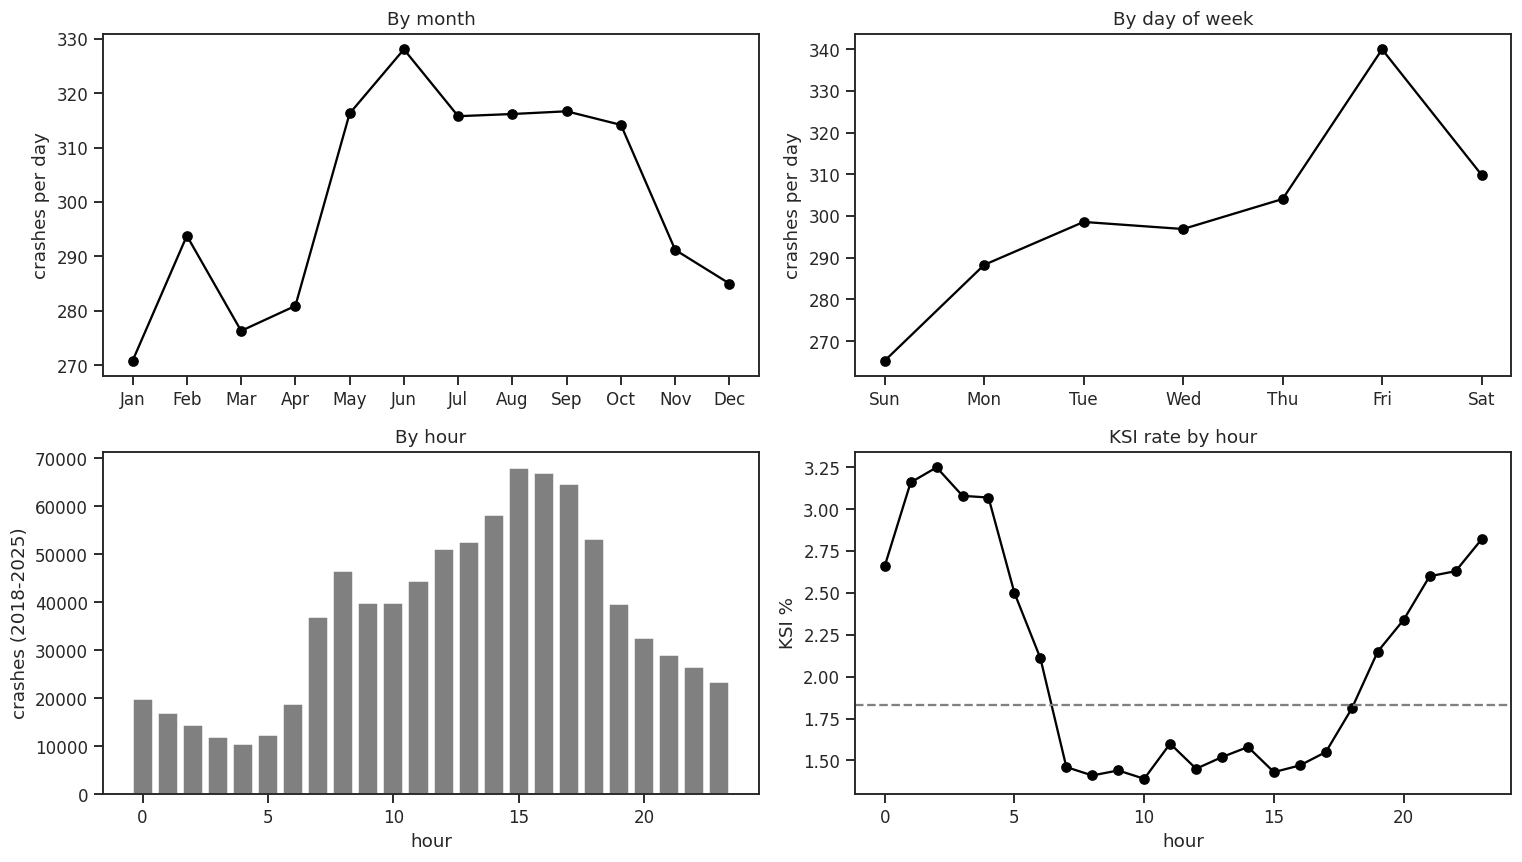

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(by_month.index.astype(str), by_month["crashes_per_day"], "o-", color="black")
axes[0, 0].set(title="By month", ylabel="crashes per day")
axes[0, 1].plot(by_dow.index.astype(str), by_dow["crashes_per_day"], "o-", color="black")
axes[0, 1].set(title="By day of week", ylabel="crashes per day")
axes[1, 0].bar(by_hour.index, by_hour["crashes"], color="grey")
axes[1, 0].set(title="By hour", xlabel="hour", ylabel="crashes (2018-2025)")
by_hour["ksi_pct"].plot(ax=axes[1, 1], marker="o", color="black", title="KSI rate by hour", ylabel="KSI %")
axes[1, 1].axhline(city_ksi, ls="--", color="grey")
fig.tight_layout()

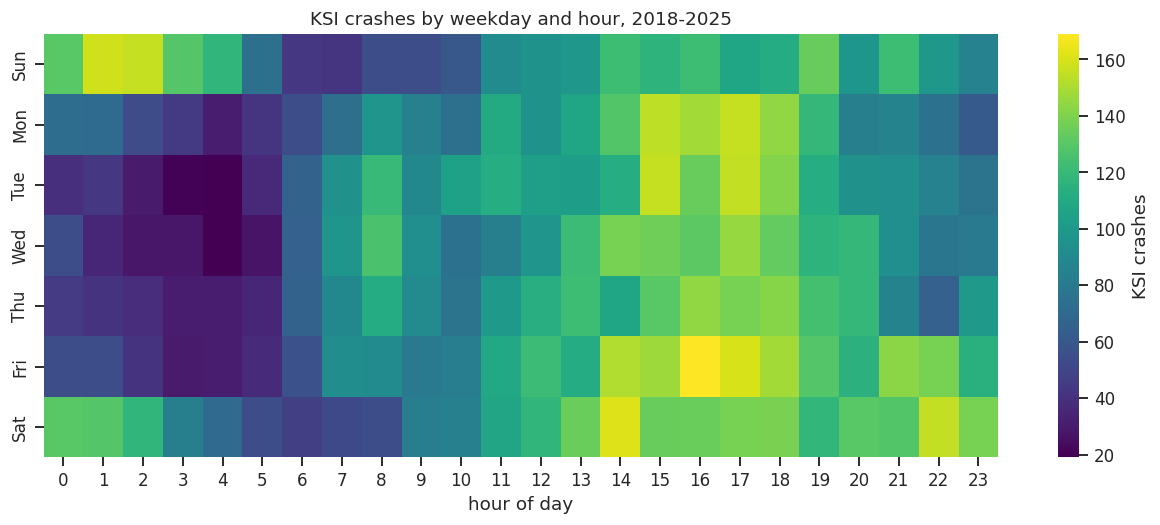

In [40]:
ksi_crashes = crashes[crashes["ksi"] == 1]
heat = pd.crosstab(ksi_crashes["dow"], ksi_crashes["hour"])
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(heat, cmap="viridis", cbar_kws={"label": "KSI crashes"}, ax=ax)
ax.set(title="KSI crashes by weekday and hour, 2018-2025", xlabel="hour of day", ylabel="");

In [41]:
display(heat.stack().nlargest(8).rename("n").reset_index())
night = ksi_crashes["hour"].ge(21) | ksi_crashes["hour"].le(4)
weekend_night = (ksi_crashes["dow"].isin(["Sat", "Sun"]) & ksi_crashes["hour"].le(4)) | (ksi_crashes["dow"].isin(["Fri", "Sat"]) & ksi_crashes["hour"].ge(21))
print(f"KSI crashes: {len(ksi_crashes):,}")
print(f"night share of KSI (%): {100 * night.mean():.1f}")
print(f"weekend night share of KSI (%): {100 * weekend_night.mean():.1f}")
print(f"night share of all crashes (%): {100 * (crashes['hour'].ge(21) | crashes['hour'].le(4)).mean():.1f}")

,dow,hour,n
0,Fri,16,169
1,Sat,14,161
2,Fri,17,160
3,Sun,1,158
4,Sun,2,156
5,Mon,17,156
6,Tue,15,156
7,Tue,17,155


KSI crashes: 16,017
night share of KSI (%): 26.9
weekend night share of KSI (%): 12.7
night share of all crashes (%): 17.4


**Interpretation:** The month, weekday and hour tables distinguish total crash counts, KSI counts, crash rates and calendar-day-normalized counts. A high crash count can reflect high travel volume, while a high KSI proportion is severity conditional on a crash. Without hourly or seasonal traffic exposure, neither is a per-trip risk estimate. Use the current tables and plots to specify deployment windows.


### Daily series

Looking at daily counts as a time series shows the weekly cycle and the 2020 drop. The ACF of daily crash counts should have spikes every 7 days if the weekly pattern is real.

days: 2,922 (2018-01-01 to 2025-12-31)


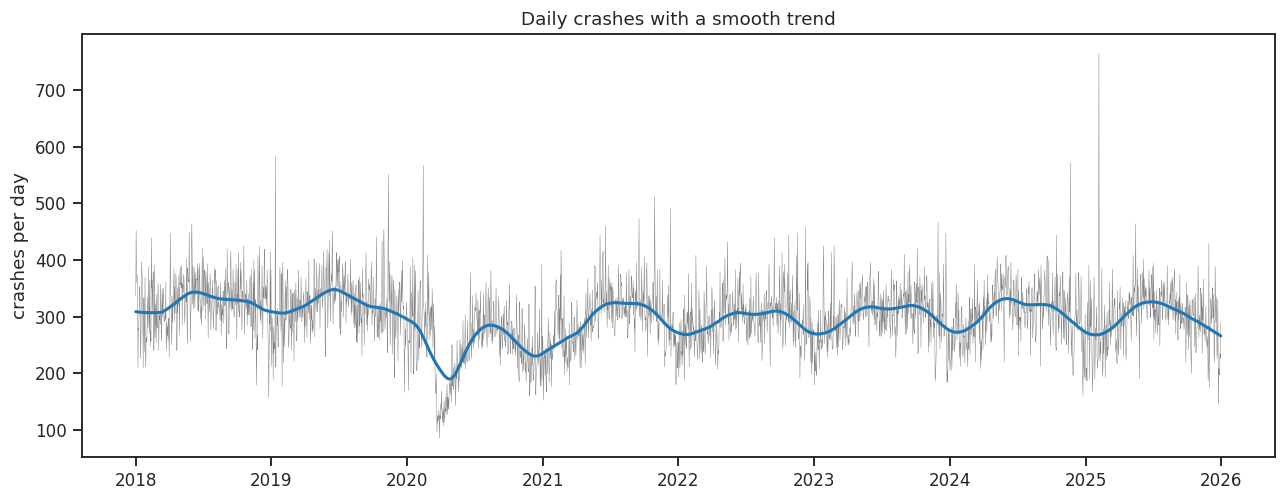

In [42]:
daily = crashes.resample("D", on="date").size()
daily_ksi = ksi_crashes.resample("D", on="date").size().reindex(daily.index, fill_value=0)
print(f"days: {len(daily):,} ({daily.index.min():%Y-%m-%d} to {daily.index.max():%Y-%m-%d})")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily.index, daily.values, lw=0.3, color="grey")
ax.plot(daily.index, lowess(daily.values, np.arange(len(daily)), frac=0.05, return_sorted=False), color="tab:blue", lw=2)
ax.set(title="Daily crashes with a smooth trend", ylabel="crashes per day");

daily crashes ACF at lags 1, 6, 7, 14: [0.52, 0.391, 0.511, 0.474]
daily KSI ACF at lags 1, 6, 7, 14: [0.208, 0.144, 0.172, 0.172]


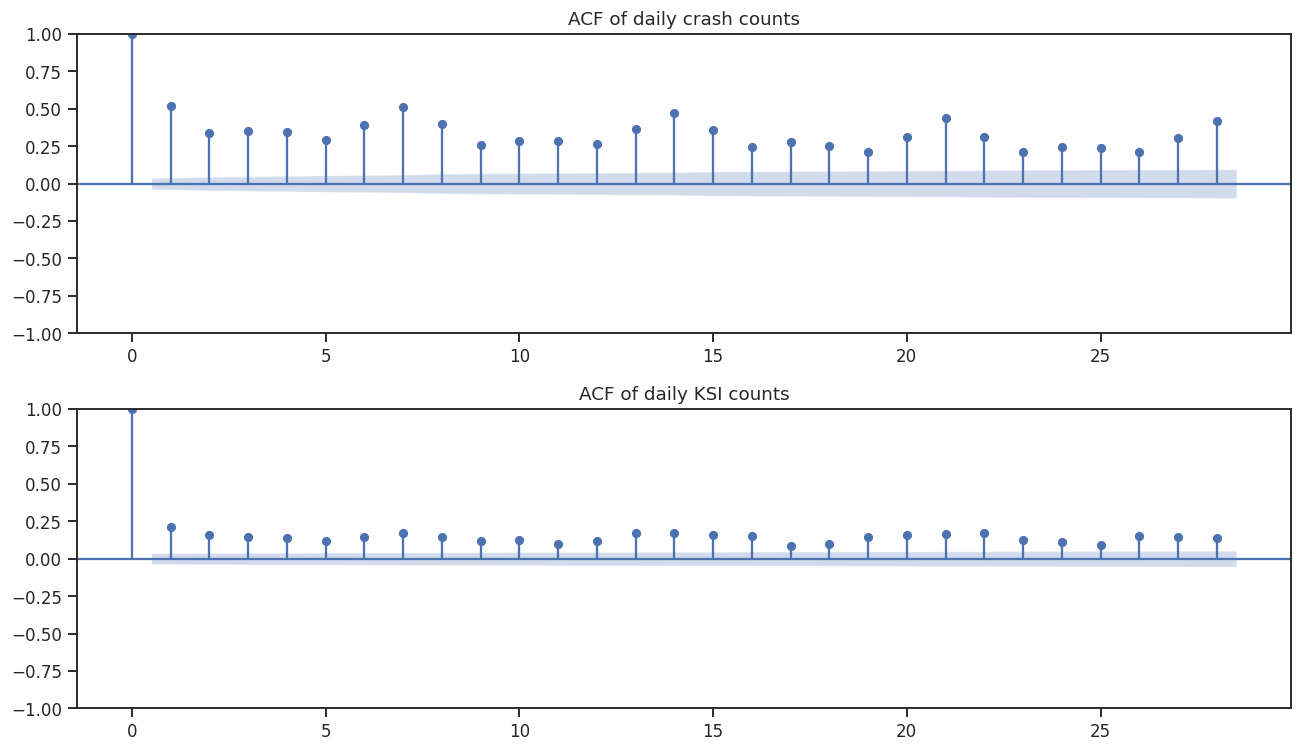

In [43]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(daily, lags=28, ax=axes[0], title="ACF of daily crash counts")
plot_acf(daily_ksi, lags=28, ax=axes[1], title="ACF of daily KSI counts")
fig.tight_layout()
lags = [1, 6, 7, 14]
print("daily crashes ACF at lags 1, 6, 7, 14:", acf(daily, nlags=14)[lags].round(3).tolist())
print("daily KSI ACF at lags 1, 6, 7, 14:", acf(daily_ksi, nlags=14)[lags].round(3).tolist())

In [44]:
# biggest spike days and the share of their crashes on snow or ice
spikes = crashes.assign(snow_ice=crashes["ROADWAY_SURFACE_COND"].isin(["SNOW OR SLUSH", "ICE"])).groupby("day").agg(crashes=("ksi", "size"), snow_ice_pct=("snow_ice", "mean"), ksi=("ksi", "sum"))
display(spikes.nlargest(6, "crashes").assign(snow_ice_pct=lambda t: (100 * t["snow_ice_pct"]).round(1), ksi=lambda t: t["ksi"].astype(int)))
print(f"median daily crashes: {daily.median():.0f}")

,crashes,snow_ice_pct,ksi
day,,,
2025-02-06,765,67.3,3
2019-01-12,583,78.4,4
2024-11-21,572,65.0,5
2020-02-14,567,25.6,10
2019-11-12,551,59.5,6
2021-10-29,512,0.0,8


median daily crashes: 303


**Verified findings from saved outputs:** The daily series covers 2,922 days. Median daily crashes = 303. The lag-7 crash-count autocorrelation is 0.511, consistent with a weekly cycle. The largest daily spike is 765 crashes on February 6, 2025, with 67.3% recorded on snow/ice. This is descriptive; traffic volume, weather exposure and reporting may explain some changes.


### Q2.2 Beat hotspots

Police beats are the location unit. The data has no traffic volume or road length per beat, so a hotspot here means many crashes, not a high risk per car. I rank beats by total crashes and by KSI crashes, then check whether a beat's KSI rate is clearly above the citywide rate (CI lower bound above it).

In [45]:
lat = pd.to_numeric(crashes["LATITUDE"], errors="coerce")
lon = pd.to_numeric(crashes["LONGITUDE"], errors="coerce")
beats = (crashes.assign(lat=lat.where(lat > 41.6), lon=lon.where(lon < -87.5))
         .groupby("beat")
         .agg(crashes=("ksi", "size"), injury=("injury", "sum"), ksi=("ksi", "sum"), fatal=("fatal", "sum"), lat=("lat", "median"), lon=("lon", "median"))
         .astype({"injury": int, "ksi": int, "fatal": int}))
beats["ksi_pct"] = (100 * beats["ksi"] / beats["crashes"]).round(2)
beats["lo"] = (100 * proportion_confint(beats["ksi"], beats["crashes"], method="wilson")[0]).round(2)
beats["above_city"] = beats["crashes"].ge(1000) & beats["lo"].gt(city_ksi)
print(f"beats: {len(beats)} | median crashes per beat: {beats['crashes'].median()}")
display(beats.nlargest(10, "crashes")[["crashes", "injury", "ksi", "fatal", "ksi_pct"]])
display(beats.nlargest(15, "ksi")[["crashes", "ksi", "fatal", "ksi_pct", "lo"]])

beats: 276 | median crashes per beat: 2853.5


,crashes,injury,ksi,fatal,ksi_pct
beat,,,,,
1834,10026,1218,123,5,1.23
813,8733,1116,106,8,1.21
114,8708,1243,174,8,2.00
815,8190,997,115,13,1.40
1831,7560,974,92,4,1.22
833,6958,937,101,5,1.45
122,6740,961,116,3,1.72
834,6628,993,135,15,2.04
2512,6600,837,101,4,1.53


,crashes,ksi,fatal,ksi_pct,lo
beat,,,,,
114,8708,174,8,2.00,1.72
834,6628,135,15,2.04,1.72
331,5509,134,9,2.43,2.06
1533,4530,130,12,2.87,2.42
411,4848,128,10,2.64,2.23
1622,6000,123,5,2.05,1.72
1834,10026,123,5,1.23,1.03
2533,6422,120,8,1.87,1.57
412,4585,119,10,2.60,2.17


In [46]:
def top_share(s, k):
    return round(100 * s.nlargest(k).sum() / s.sum(), 1)


top15_crashes = set(beats.nlargest(15, "crashes", keep="all").index)
top15_ksi = set(beats.nlargest(15, "ksi", keep="all").index)
print(f"share of all crashes in top 25 beats (%): {top_share(beats['crashes'], 25)}")
print(f"share of KSI crashes in top 25 KSI beats (%): {top_share(beats['ksi'], 25)}")
print(f"beats with 1000+ crashes: {beats['crashes'].ge(1000).sum()}")
print(f"beats (1000+ crashes) with KSI rate clearly above city: {beats['above_city'].sum()}")
print(f"overlap of top 15 by crashes and top 15 by KSI: {len(top15_crashes & top15_ksi)}")

share of all crashes in top 25 beats (%): 18.4
share of KSI crashes in top 25 KSI beats (%): 17.8
beats with 1000+ crashes: 269
beats (1000+ crashes) with KSI rate clearly above city: 56
overlap of top 15 by crashes and top 15 by KSI: 7


Is the ranking stable, or just noise from one bad year? I compare beat KSI counts in 2018-2021 with 2022-2025.

In [47]:
halves = crashes.assign(period=np.where(crashes["year"] <= 2021, "2018-21", "2022-25")).pivot_table(index="beat", columns="period", values="ksi", aggfunc=["size", "sum"], fill_value=0)
first_ksi, second_ksi = halves[("sum", "2018-21")], halves[("sum", "2022-25")]
print(f"spearman corr, crashes: {spearmanr(halves[('size', '2018-21')], halves[('size', '2022-25')]).statistic:.3f}")
print(f"spearman corr, KSI: {spearmanr(first_ksi, second_ksi).statistic:.3f}")
print(f"top 15 KSI beats in both halves: {len(set(first_ksi.nlargest(15, keep='all').index) & set(second_ksi.nlargest(15, keep='all').index))}")

spearman corr, crashes: 0.975
spearman corr, KSI: 0.793
top 15 KSI beats in both halves: 8


beats without a valid location: 5


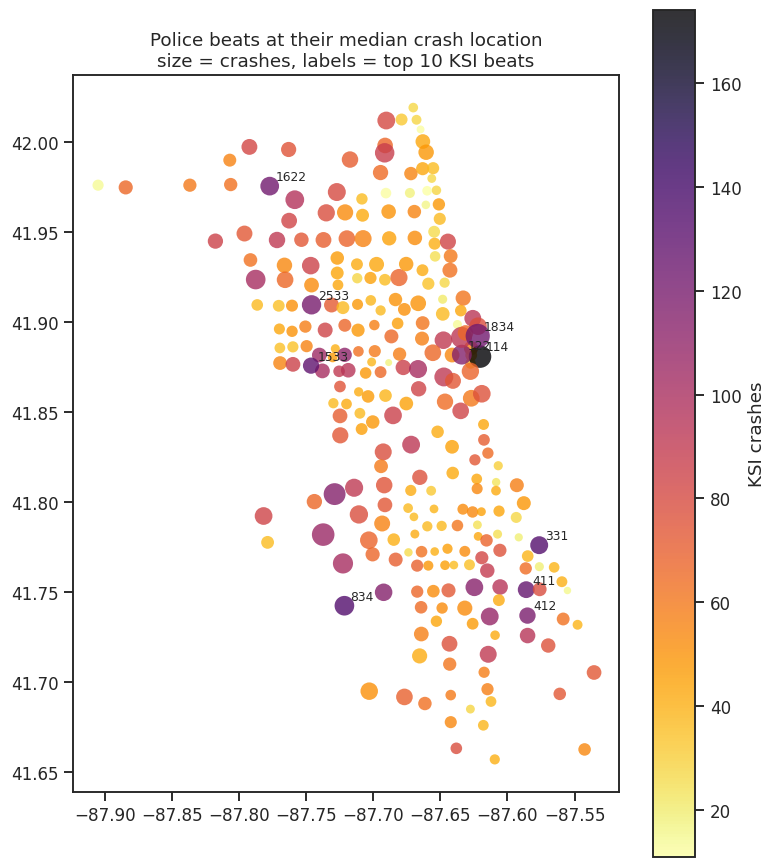

In [48]:
located = beats.dropna(subset=["lat", "lon"])
print(f"beats without a valid location: {len(beats) - len(located)}")
fig, ax = plt.subplots(figsize=(8, 10))
points = ax.scatter(located["lon"], located["lat"], s=located["crashes"] / 40, c=located["ksi"], cmap="inferno_r", alpha=0.8, edgecolor="none")
for beat, row in located.nlargest(10, "ksi").iterrows():
    ax.annotate(beat, (row["lon"], row["lat"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
fig.colorbar(points, ax=ax, label="KSI crashes")
ax.set_aspect(1 / np.cos(np.deg2rad(41.85)))
ax.set_title("Police beats at their median crash location\nsize = crashes, labels = top 10 KSI beats");

**Verified findings from saved outputs:** Highest crash counts: beats 1834 (10,026), 813 (8,733), and 114 (8,708). Highest KSI counts: beats 114 (174), 834 (135), and 331 (134). Seven beats overlap between the top 15 crash-count and KSI-count lists. Spearman rank correlation across 2018–2021 versus 2022–2025 is 0.975 for crash counts and 0.793 for KSI counts. Five beats lack valid plotted median coordinates. These are **counts of reported crashes**, not traffic-exposure-adjusted danger rankings; median point locations are schematic, not beat boundaries.


## Executive synthesis and recommendations for CDOT

**Coverage and definitions.** 877,919 crashes, 1,792,368 vehicle units and 1,927,651 people dated 2018–2025; 16,017 crashes with fatal/incapacitating injuries (1.83% of crashes with known severity), 980 fatal crashes, and 1,063 recorded fatalities. Crash-level and person-level KSI counts are different measures and must not be combined. The analysis is based on reported crashes and cannot estimate the risk of a crash per trip or mile.

1. **Prioritize pedestrian and cyclist protection.** In the person-level complete-case model, pedestrian and cyclist adjusted KSI odds were substantially higher than for drivers (OR 27.14 and 15.07, respectively). Prioritize site-level reviews of pedestrian/cyclist KSI locations, crossings, turning movements and protected infrastructure. These odds ratios do not measure injury risk for all travelers.
2. **Target speed management and high-severity corridors.** Crash-level KSI rates increase from 0.86% on roads posted 5–20 mph to 3.34% on roads posted 40+ mph. Examine actual speeds, geometry, crash types and pedestrian exposure before choosing specific interventions.
3. **Audit high-KSI intersection designs and lighting.** Four-way and five-point intersections have elevated crash-conditional KSI rates; the adjusted person model also finds higher KSI odds in darkness/low-light categories than its daylight reference. Evaluate crossings, turn conflicts, lighting coverage and crash counts at individual sites before recommending upgrades.
4. **Use police beats to triage, then investigate specific sites.** Beat 114 has the highest KSI count (174), followed by 834 (135) and 331 (134). Beat 1834 has the most total crashes (10,026) but a lower KSI proportion (1.23%). Combine crash counts, severity and traffic/pedestrian exposure rather than relying on one rank.
5. **Deploy seasonal and time-specific responses based on both frequency and severity.** The daily series shows weekly patterns and large snow/ice-associated crash spikes. Use the notebook’s month/day/hour tables to specify schedules, and validate against traffic volume and weather data.
6. **Improve data quality and evaluation.** Road-defect status is missing in 20.4% of crash records, and the person-level complete-case model excludes ~31.3% of people. Audit missingness, apply crash-clustered uncertainty where possible, and use held-out and temporal validation. Evaluate interventions prospectively, rather than treating these observational associations as causal estimates.

**Limitations:** Police-reporting and coding bias; no travel exposure, road length or vehicle miles; potential temporal changes in reporting; missing covariates and selection bias; multiple people/vehicles within a crash; post-crash cause, airbag and ejection fields; lack of geographic roadway network and beat boundaries. Significance does not imply policy impact.

**Reproducibility:** Run the edited notebook top to bottom in a Colab runtime with the three complete CSVs. Any saved output in an unchanged cell represents the uploaded execution; new or modified cells have no output until rerun.


# Report & presentation extensions — run after the original analysis
These are **additional analyses**, not pre-verified results. Run the notebook in order, then use the printed tables/figures to update your report. The outcome is KSI **conditional on a recorded crash**, not risk per trip or causal impact. Confidence intervals are descriptive unless explicitly adjusted. The new analyses use the existing `crashes`, `people`, and `beats` dataframes; no CSV redownload is required.

In [49]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint
from IPython.display import display
OUT = Path('/content/drive/MyDrive/ChicagoTrafficData/report_outputs') if Path('/content/drive/MyDrive/ChicagoTrafficData').exists() else Path('/content/report_outputs')
OUT.mkdir(parents=True, exist_ok=True)
print('Report figures and tables will be saved to:', OUT)
assert len(crashes) > 100_000 and {'ksi','year','speed_cat','LIGHTING_CONDITION'}.issubset(crashes.columns)


Report figures and tables will be saved to: /content/drive/MyDrive/ChicagoTrafficData/report_outputs


## Extension 1 — annual crash volume and KSI severity
This separates the *number* of recorded crashes from the *percentage of recorded crashes* involving a fatality or incapacitating injury. Changes in reporting, traffic exposure, and the pandemic limit causal interpretation.

,year,crashes,ksi,ksi_rate_pct,low_pct,high_pct
0,2018,118728,2255.0,1.899,1.823,1.979
1,2019,117499,2113.0,1.798,1.724,1.876
2,2020,91860,2022.0,2.201,2.108,2.298
3,2021,108519,2187.0,2.015,1.933,2.101
4,2022,108119,2093.0,1.936,1.855,2.020
5,2023,110493,2035.0,1.842,1.764,1.923
6,2024,111805,1739.0,1.555,1.485,1.630
7,2025,108902,1573.0,1.444,1.375,1.517


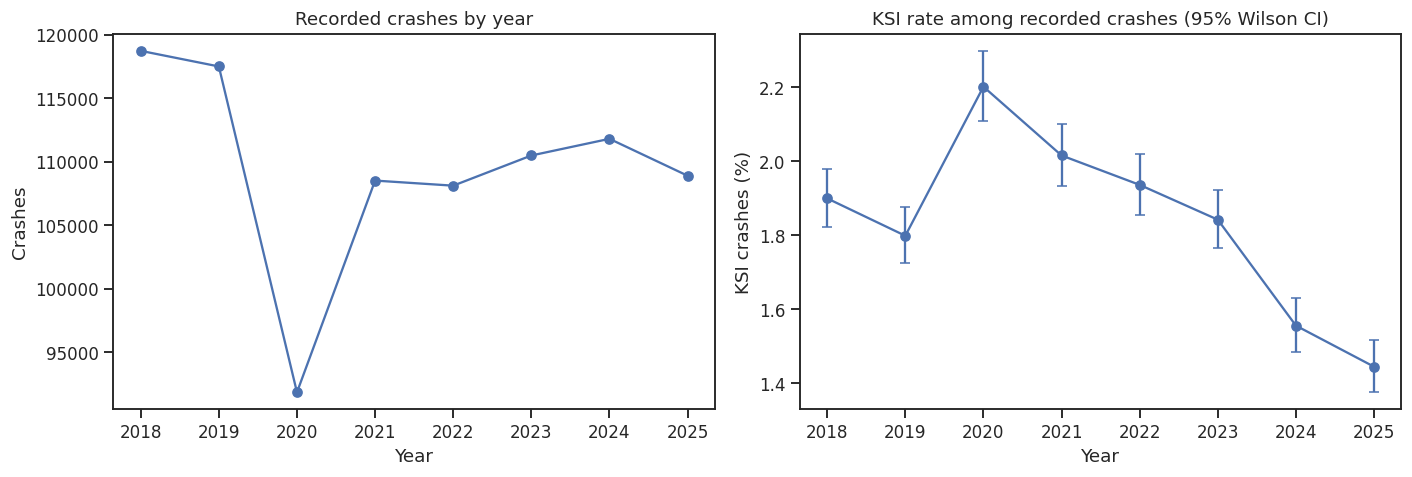

In [50]:
annual = crashes.dropna(subset=['year','ksi']).groupby('year',observed=True)['ksi'].agg(crashes='size',ksi='sum').reset_index()
annual['ksi_rate_pct']=100*annual.ksi/annual.crashes
lo,hi=proportion_confint(annual.ksi,annual.crashes,alpha=.05,method='wilson')
annual['low_pct'],annual['high_pct']=100*lo,100*hi
annual.to_csv(OUT/'annual_ksi_trends.csv',index=False)
display(annual.round(3))
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
ax[0].plot(annual.year,annual.crashes,marker='o');ax[0].set(title='Recorded crashes by year',xlabel='Year',ylabel='Crashes')
ax[1].errorbar(annual.year,annual.ksi_rate_pct,yerr=[annual.ksi_rate_pct-annual.low_pct,annual.high_pct-annual.ksi_rate_pct],fmt='o-',capsize=3)
ax[1].set(title='KSI rate among recorded crashes (95% Wilson CI)',xlabel='Year',ylabel='KSI crashes (%)')
fig.tight_layout();fig.savefig(OUT/'annual_ksi_trends.png',dpi=180,bbox_inches='tight');plt.show()


## Extension 2 — posted speed × lighting: descriptive interaction
Compare KSI proportions in daylight vs darkness across posted-speed groups. **Not** a comparison of equivalent roads or traffic exposure. To avoid sparse groups, show only groups with at least 500 crashes. A nonparallel pattern is *suggestive* of interaction, not a formal test.

,speed_cat,light_group,n,ksi,ksi_pct,low_pct,high_pct
0,5-20,Darkness,21437,231.0,1.078,0.948,1.225
1,5-20,Daylight,63556,544.0,0.856,0.787,0.931
2,25,Darkness,15684,322.0,2.053,1.843,2.287
3,25,Daylight,36221,498.0,1.375,1.260,1.500
4,30,Darkness,172644,4731.0,2.740,2.664,2.818
5,30,Daylight,413251,6747.0,1.633,1.594,1.672
6,35,Darkness,16590,541.0,3.261,3.001,3.542
7,35,Daylight,34706,853.0,2.458,2.300,2.626
8,40+,Darkness,5641,267.0,4.733,4.209,5.319
9,40+,Daylight,8881,227.0,2.556,2.248,2.905


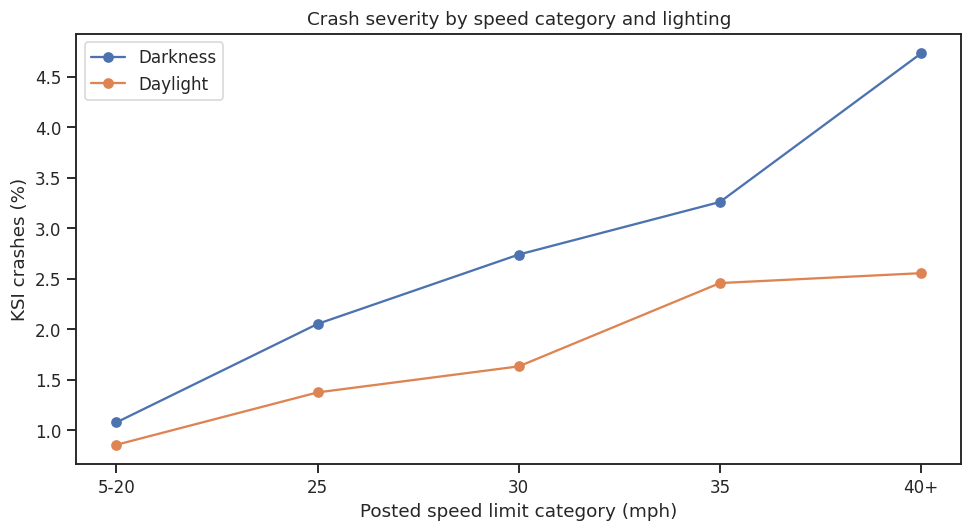

In [51]:
light_raw=crashes['LIGHTING_CONDITION'].astype('string').str.upper()
light_group=np.select([light_raw.eq('DAYLIGHT').fillna(False),light_raw.str.contains('DARKNESS',na=False)],['Daylight','Darkness'],default='Other/unknown')
speedlight=crashes.assign(light_group=light_group).loc[lambda x:x.light_group.isin(['Daylight','Darkness'])].dropna(subset=['ksi','speed_cat'])
speedlight_table=speedlight.groupby(['speed_cat','light_group'],observed=True)['ksi'].agg(n='size',ksi='sum').reset_index()
speedlight_table['ksi_pct']=100*speedlight_table.ksi/speedlight_table.n
lo,hi=proportion_confint(speedlight_table.ksi,speedlight_table.n,method='wilson')
speedlight_table['low_pct'],speedlight_table['high_pct']=100*lo,100*hi
speedlight_table.to_csv(OUT/'speed_lighting_ksi.csv',index=False)
display(speedlight_table.round(3))
fig,ax=plt.subplots(figsize=(9,5))
for label,g in speedlight_table.loc[lambda t:t.n>=500].groupby('light_group'):
    g=g.sort_values('speed_cat');ax.plot(g.speed_cat.astype(str),g.ksi_pct,marker='o',label=label)
ax.set(xlabel='Posted speed limit category (mph)',ylabel='KSI crashes (%)',title='Crash severity by speed category and lighting');ax.legend();fig.tight_layout()
fig.savefig(OUT/'speed_lighting_ksi.png',dpi=180,bbox_inches='tight');plt.show()


### Optional adjusted interaction model (crash level)
Uses the same recorded-crash population with complete speed and lighting information, controls for year and crash type, and estimates whether speed-related associations vary by lighting. It does **not** identify the causal effect of speed or darkness. If computation is slow, the descriptive comparison above is sufficient for the report.

In [52]:
import statsmodels.formula.api as smf
import statsmodels.api as sm
inter=crashes.assign(light_group=light_group).loc[lambda d:d.light_group.isin(['Daylight','Darkness']),['ksi','speed_cat','year','FIRST_CRASH_TYPE','light_group']].dropna().copy()
# Retain common crash types; rare categories grouped to avoid unstable coefficients.
types=inter.FIRST_CRASH_TYPE.value_counts();inter['crash_type_group']=inter.FIRST_CRASH_TYPE.where(inter.FIRST_CRASH_TYPE.isin(types[types>=2000].index),'Other')
inter['speed_cat']=inter.speed_cat.astype(str)
inter=inter.loc[inter.speed_cat.ne('nan')]
formula='ksi ~ C(speed_cat, Treatment(reference="30"))*C(light_group, Treatment(reference="Daylight")) + C(year) + C(crash_type_group)'
try:
    fit_inter=smf.glm(formula,data=inter,family=sm.families.Binomial()).fit(maxiter=100)
    interactions=fit_inter.summary2().tables[1].loc[lambda d:d.index.str.contains(':')]
    display(interactions)
    interactions.to_csv(OUT/'adjusted_speed_lighting_interactions.csv')
    print('Interaction coefficients are log odds ratios; interpret with CI and group sample sizes, not as causal effects.')
except Exception as e:
    print('Adjusted interaction model did not complete:',type(e).__name__,str(e)[:350])


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
"C(speed_cat, Treatment(reference=""30""))[T.25]:C(light_group, Treatment(reference=""Daylight""))[T.Darkness]",-0.040500,0.076579,-0.528867,0.596898,-0.190592,0.109592
"C(speed_cat, Treatment(reference=""30""))[T.35]:C(light_group, Treatment(reference=""Daylight""))[T.Darkness]",-0.293521,0.060827,-4.825481,0.000001,-0.412740,-0.174302
"C(speed_cat, Treatment(reference=""30""))[T.40+]:C(light_group, Treatment(reference=""Daylight""))[T.Darkness]",-0.076335,0.095911,-0.795895,0.426093,-0.264318,0.111648
"C(speed_cat, Treatment(reference=""30""))[T.5-20]:C(light_group, Treatment(reference=""Daylight""))[T.Darkness]",-0.194027,0.082547,-2.350502,0.018748,-0.355816,-0.032238


Interaction coefficients are log odds ratios; interpret with CI and group sample sizes, not as causal effects.


## Extension 3 — police beats: excess KSI relative to crash count
For each beat, expected KSI count = its recorded crashes × the citywide KSI rate. Compare observed/expected only for beats with at least 1,000 crashes, and report Wilson intervals. **Important:** the citywide reference includes the beat itself, and the calculation is not adjusted for road mix, demographics, traffic volume, or spatial dependence; use this as a screening tool, not a causal or definitive risk ranking.

,beat,crashes,ksi,expected_ksi,observed_expected,ksi_pct,low_pct,high_pct
26,1132,2310,90.0,42.240,2.131,3.896,3.181,4.765
213,523,2290,78.0,41.875,1.863,3.406,2.738,4.231
156,231,1327,45.0,24.265,1.855,3.391,2.544,4.507
139,213,2160,73.0,39.497,1.848,3.380,2.697,4.228
21,1123,1924,63.0,35.182,1.791,3.274,2.568,4.167
185,311,1321,43.0,24.156,1.780,3.255,2.426,4.356
0,1011,2338,75.0,42.752,1.754,3.208,2.567,4.002
20,1122,3497,111.0,63.945,1.736,3.174,2.643,3.809
238,724,1277,40.0,23.351,1.713,3.132,2.309,4.237
152,2233,1920,59.0,35.109,1.680,3.073,2.390,3.943


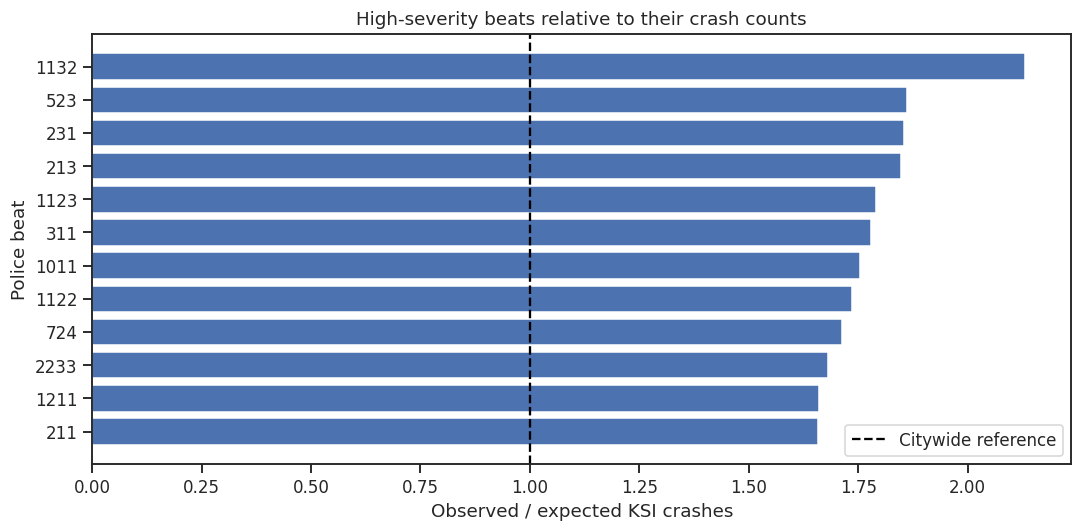

In [53]:
beat_ext=crashes.dropna(subset=['beat','ksi']).groupby('beat')['ksi'].agg(crashes='size',ksi='sum').reset_index()
city=crashes.ksi.mean()
beat_ext['expected_ksi']=beat_ext.crashes*city
beat_ext['observed_expected']=beat_ext.ksi/beat_ext.expected_ksi
beat_ext['ksi_pct']=100*beat_ext.ksi/beat_ext.crashes
lo,hi=proportion_confint(beat_ext.ksi,beat_ext.crashes,method='wilson')
beat_ext['low_pct'],beat_ext['high_pct']=100*lo,100*hi
beat_ext=beat_ext.loc[beat_ext.crashes>=1000].sort_values('observed_expected',ascending=False)
beat_ext.to_csv(OUT/'beat_excess_ksi.csv',index=False)
display(beat_ext.head(15).round(3))
fig,ax=plt.subplots(figsize=(10,5))
top=beat_ext.head(12).iloc[::-1]
ax.barh(top.beat.astype(str),top.observed_expected);ax.axvline(1,color='black',linestyle='--',label='Citywide reference')
ax.set(xlabel='Observed / expected KSI crashes',ylabel='Police beat',title='High-severity beats relative to their crash counts');ax.legend();fig.tight_layout()
fig.savefig(OUT/'beat_excess_ksi.png',dpi=180,bbox_inches='tight');plt.show()


## Extension 4 — pedestrian and cyclist severity by speed and lighting
A focused descriptive comparison of **recorded people**. Person-level injury KSI is distinct from the crash-level outcome. Small cells are excluded from the plotted comparison. Because multiple people may share a crash, the simple Wilson intervals are not cluster-adjusted.

,person_type,speed_cat,light_group,n,ksi,ksi_pct
0,BICYCLE,5-20,Darkness,151,12.0,7.947
1,BICYCLE,5-20,Daylight,823,46.0,5.589
2,BICYCLE,25,Darkness,188,28.0,14.894
3,BICYCLE,25,Daylight,832,70.0,8.413
4,BICYCLE,30,Darkness,2611,295.0,11.298
5,BICYCLE,30,Daylight,8876,743.0,8.371
6,BICYCLE,35,Darkness,229,32.0,13.974
7,BICYCLE,35,Daylight,565,58.0,10.265
10,PEDESTRIAN,5-20,Darkness,651,101.0,15.515
11,PEDESTRIAN,5-20,Daylight,1924,243.0,12.630


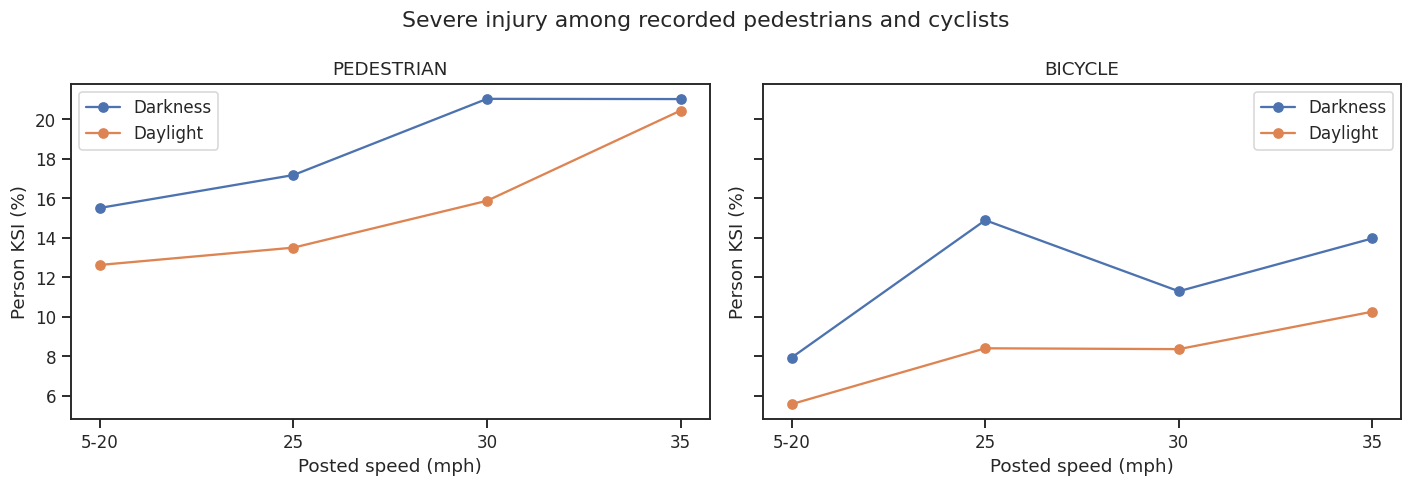

In [54]:
vr=people.loc[people.person_type.isin(['PEDESTRIAN','BICYCLE'])].copy()
vr['light_group']=np.select([vr.LIGHTING_CONDITION.astype('string').str.upper().eq('DAYLIGHT').fillna(False),vr.LIGHTING_CONDITION.astype('string').str.upper().str.contains('DARKNESS',na=False)],['Daylight','Darkness'],default='Other/unknown')
vr=vr.loc[vr.light_group.isin(['Daylight','Darkness'])].dropna(subset=['ksi','speed_cat'])
vr_table=vr.groupby(['person_type','speed_cat','light_group'],observed=True)['ksi'].agg(n='size',ksi='sum').reset_index()
vr_table['ksi_pct']=100*vr_table.ksi/vr_table.n
vr_table.to_csv(OUT/'vulnerable_road_users.csv',index=False)
display(vr_table.loc[vr_table.n>=100].sort_values(['person_type','speed_cat','light_group']).round(3))
fig,axes=plt.subplots(1,2,figsize=(13,4.5),sharey=True)
for ax,person in zip(axes,['PEDESTRIAN','BICYCLE']):
    subset=vr_table.loc[(vr_table.person_type==person)&(vr_table.n>=100)]
    for lighting,g in subset.groupby('light_group'):
        ax.plot(g.speed_cat.astype(str),g.ksi_pct,marker='o',label=lighting)
    ax.set(title=person,xlabel='Posted speed (mph)',ylabel='Person KSI (%)');ax.legend()
fig.suptitle('Severe injury among recorded pedestrians and cyclists');fig.tight_layout()
fig.savefig(OUT/'vulnerable_road_users.png',dpi=180,bbox_inches='tight');plt.show()


## Report/PPT checklist after running extensions
- **Main findings:** keep the existing adjusted crash- and person-level logistic results; do not replace them with raw comparisons.
- **New visuals:** annual crash count vs KSI rate, speed × lighting, observed/expected beat severity, pedestrian/cyclist subgroup.
- **Use the actual output:** copy numbers from the new CSV tables. Do not claim an interaction or a trend is statistically established unless supported by its model/test.
- **Avoid overclaiming:** conditional on a *recorded* crash; missing/unknown values, traffic exposure, potential reporting changes, crash clustering, and observational confounding matter.
- **Model improvement option:** temporal validation and crash-clustered uncertainty remain worthwhile, but are not automatically more informative than the four new report-focused analyses. They are deliberately not mixed into this extension to keep runtime manageable.

In [55]:
# FINAL VALIDATION — SETUP
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

from IPython.display import display
from scipy.stats import spearmanr, norm
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

OUT = Path("/content/drive/MyDrive/ChicagoTrafficData/report_outputs")
OUT.mkdir(parents=True, exist_ok=True)

required = [
    "crashes", "people", "person_model",
    "person_fit", "person_formula", "person_refs"
]

for name in required:
    assert name in globals(), f"Missing {name}. Run its earlier cell first."

print("Setup successful!")
print("Crashes:", len(crashes))
print("People:", len(people))
print("Regression sample:", len(person_model))
print("Output folder:", OUT)

Setup successful!
Crashes: 877919
People: 1927651
Regression sample: 1323898
Output folder: /content/drive/MyDrive/ChicagoTrafficData/report_outputs


In [56]:
# VALIDATION 1A — MISSING DATA

included = pd.Series(
    people.index.isin(person_model.index),
    index=people.index,
    name="complete_case"
)

selection = (
    people.assign(complete_case=included)
    .groupby(["complete_case", "person_type"], observed=True)["ksi"]
    .agg(n="count", ksi="sum", rate="mean")
    .reset_index()
)

selection["ksi_pct"] = selection["rate"] * 100

print("Complete-case retention:", round(included.mean() * 100, 2), "%")

display(
    selection.sort_values(["person_type", "complete_case"]).round(3)
)

print("\nKSI among included versus excluded records:")

display(
    people.assign(complete_case=included)
    .groupby("complete_case")["ksi"]
    .agg(["count", "sum", "mean"])
)

missing = (
    people[
        ["ksi", "person_type", "age_cat", "sex",
         "speed_cat", "LIGHTING_CONDITION"]
    ]
    .isna()
    .mean()
    .mul(100)
    .rename("missing_pct")
)

display(missing.to_frame().round(2))

selection.to_csv(
    OUT / "validation_missingness_by_person_type.csv",
    index=False
)

missing.to_csv(OUT / "validation_variable_missingness.csv")

Complete-case retention: 68.68 %


,complete_case,person_type,n,ksi,rate,ksi_pct
0,False,BICYCLE,2611,86.0,0.033,3.294
5,True,BICYCLE,12907,1303.0,0.101,10.095
1,False,DRIVER,437351,613.0,0.001,0.140
6,True,DRIVER,1057539,8610.0,0.008,0.814
2,False,Other,1005,12.0,0.012,1.194
7,True,Other,772,51.0,0.066,6.606
3,False,PASSENGER,159533,734.0,0.005,0.460
8,True,PASSENGER,231153,3310.0,0.014,1.432
4,False,PEDESTRIAN,2697,352.0,0.131,13.052
9,True,PEDESTRIAN,21527,3791.0,0.176,17.610



KSI among included versus excluded records:


,count,sum,mean
complete_case,,,
False,603197,1797.0,0.002979
True,1323898,17065.0,0.012890


,missing_pct
ksi,0.03
person_type,0.00
age_cat,28.86
sex,11.00
speed_cat,0.46
LIGHTING_CONDITION,3.78


In [57]:
# VALIDATION 1B — SENSITIVITY MODEL

simple = people[
    ["ksi", "person_type", "age_cat", "sex"]
].dropna().copy()

for col in ["person_type", "age_cat", "sex"]:
    simple[col] = simple[col].astype(str)

simple = simple.loc[
    (simple["age_cat"] != "nan") &
    (simple["sex"] != "nan")
]

simple["person_type"] = simple["person_type"].where(
    simple["person_type"].isin(
        ["DRIVER", "PASSENGER", "PEDESTRIAN", "BICYCLE"]
    ),
    "Other"
)

reduced_formula = (
    'ksi ~ C(person_type, Treatment(reference="DRIVER"))'
    ' + C(age_cat, Treatment(reference="25-44"))'
    ' + C(sex, Treatment(reference="F"))'
)

reduced_fit = smf.glm(
    reduced_formula,
    data=simple,
    family=sm.families.Binomial()
).fit()

rows = []

for term in reduced_fit.params.index:
    if "person_type" in term:
        low, high = reduced_fit.conf_int().loc[term]

        rows.append({
            "term": term,
            "OR": np.exp(reduced_fit.params[term]),
            "CI_low": np.exp(low),
            "CI_high": np.exp(high)
        })

reduced_or = pd.DataFrame(rows)

print("Sensitivity model sample:", len(simple))
print("KSI cases:", int(simple.ksi.sum()))

display(reduced_or.round(3))

reduced_or.to_csv(
    OUT / "validation_reduced_model_OR.csv",
    index=False
)

Sensitivity model sample: 1364456
KSI cases: 17292


,term,OR,CI_low,CI_high
0,"C(person_type, Treatment(reference=""DRIVER""))[T.BICYCLE]",14.320,13.471,15.222
1,"C(person_type, Treatment(reference=""DRIVER""))[T.Other]",8.933,6.755,11.814
2,"C(person_type, Treatment(reference=""DRIVER""))[T.PASSENGER]",1.988,1.905,2.074
3,"C(person_type, Treatment(reference=""DRIVER""))[T.PEDESTRIAN]",27.257,26.157,28.403


In [58]:
# VALIDATION 2 — CLUSTERED CONFIDENCE INTERVALS

from statsmodels.stats.sandwich_covariance import cov_cluster

used_idx = person_fit.model.data.row_labels

crash_groups = (
    people.loc[used_idx, "CRASH_RECORD_ID"]
    .astype(str)
)

assert len(crash_groups) == len(person_fit.model.endog)

V = cov_cluster(person_fit, crash_groups)

se = np.sqrt(np.maximum(np.diag(V), 0))
coef = np.asarray(person_fit.params)
z = norm.ppf(0.975)

clustered = pd.DataFrame({
    "term": person_fit.params.index,
    "OR": np.exp(coef),
    "cluster_low": np.exp(coef - z * se),
    "cluster_high": np.exp(coef + z * se),
    "cluster_p": 2 * norm.sf(
        np.abs(
            np.divide(
                coef, se,
                out=np.zeros_like(coef),
                where=se > 0
            )
        )
    )
})

original_ci = person_fit.conf_int()

clustered["ordinary_low"] = np.exp(
    original_ci.iloc[:, 0].to_numpy()
)

clustered["ordinary_high"] = np.exp(
    original_ci.iloc[:, 1].to_numpy()
)

print("Unique crash clusters:", crash_groups.nunique())

display(
    clustered.loc[
        clustered.term.str.contains(
            "person_type|speed_cat|LIGHTING",
            regex=True
        )
    ].round(3)
)

clustered.to_csv(
    OUT / "validation_crash_clustered_OR.csv",
    index=False
)

Unique crash clusters: 694816


,term,OR,cluster_low,cluster_high,cluster_p,ordinary_low,ordinary_high
1,"C(person_type, Treatment('DRIVER'))[T.BICYCLE]",15.069,14.142,16.057,0.000,14.161,16.035
2,"C(person_type, Treatment('DRIVER'))[T.Other]",9.659,7.216,12.927,0.000,7.255,12.857
3,"C(person_type, Treatment('DRIVER'))[T.PASSENGER]",1.857,1.774,1.944,0.000,1.779,1.939
4,"C(person_type, Treatment('DRIVER'))[T.PEDESTRIAN]",27.139,25.977,28.354,0.000,26.021,28.307
10,"C(speed_cat, Treatment('30'))[T.25]",0.856,0.792,0.926,0.000,0.798,0.919
11,"C(speed_cat, Treatment('30'))[T.35]",1.382,1.297,1.472,0.000,1.310,1.458
12,"C(speed_cat, Treatment('30'))[T.40+]",2.108,1.901,2.337,0.000,1.940,2.290
13,"C(speed_cat, Treatment('30'))[T.5-20]",0.571,0.528,0.618,0.000,0.531,0.615
14,"C(LIGHTING_CONDITION, Treatment('DAYLIGHT'))[T.DARKNESS]",1.402,1.285,1.528,0.000,1.302,1.509
15,"C(LIGHTING_CONDITION, Treatment('DAYLIGHT'))[T.DARKNESS, LIGHTED R...",1.849,1.776,1.925,0.000,1.787,1.914


,train_n,test_n,test_ksi,prevalence,roc_auc,average_precision,brier
0,991931,331967,3475,0.01047,0.74812,0.07669,0.01


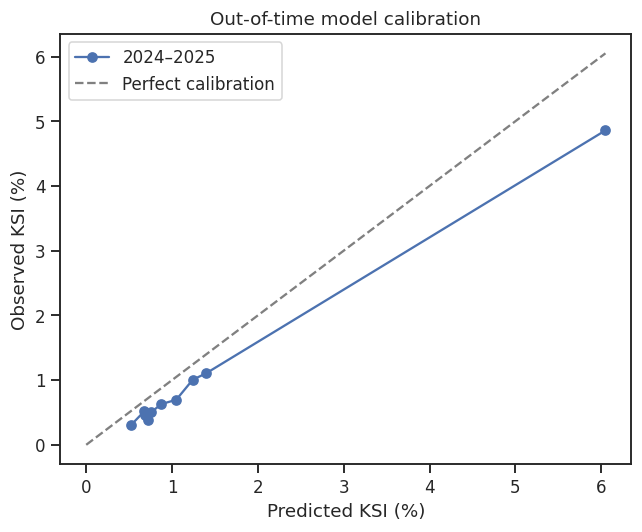

In [59]:
# VALIDATION 3 — FUTURE-YEAR MODEL PERFORMANCE

crash_dates = (
    crashes[["CRASH_RECORD_ID", "date"]]
    .drop_duplicates("CRASH_RECORD_ID")
    .set_index("CRASH_RECORD_ID")["date"]
)

model_year = people.loc[
    person_model.index, ["CRASH_RECORD_ID"]
].copy()

model_year["year"] = pd.to_datetime(
    model_year["CRASH_RECORD_ID"].map(crash_dates)
).dt.year

model_year = model_year.join(person_model)

train_time = model_year.loc[
    model_year.year <= 2023
].copy()

test_time = model_year.loc[
    model_year.year >= 2024
].copy()

assert len(train_time) > 10000
assert len(test_time) > 1000

for col in person_refs:
    levels = person_model[col].astype("category").cat.categories

    train_time[col] = pd.Categorical(
        train_time[col], categories=levels
    )

    test_time[col] = pd.Categorical(
        test_time[col], categories=levels
    )

time_fit = smf.glm(
    person_formula,
    data=train_time,
    family=sm.families.Binomial()
).fit(maxiter=100)

p_future = np.asarray(time_fit.predict(test_time))
y_future = test_time.ksi.to_numpy()

metrics = {
    "train_n": len(train_time),
    "test_n": len(test_time),
    "test_ksi": int(y_future.sum()),
    "prevalence": float(y_future.mean()),
    "roc_auc": roc_auc_score(y_future, p_future),
    "average_precision": average_precision_score(
        y_future, p_future
    ),
    "brier": brier_score_loss(y_future, p_future)
}

display(pd.DataFrame([metrics]).round(5))

pd.DataFrame([metrics]).to_csv(
    OUT / "validation_temporal_metrics.csv",
    index=False
)

cal = pd.DataFrame({"y": y_future, "p": p_future})

cal["decile"] = (
    pd.qcut(
        cal.p.rank(method="first"),
        10,
        labels=False
    ) + 1
)

calib = (
    cal.groupby("decile")
    .agg(
        n=("y", "size"),
        observed=("y", "mean"),
        predicted=("p", "mean")
    )
    .reset_index()
)

calib.to_csv(
    OUT / "validation_temporal_calibration.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(
    calib.predicted * 100,
    calib.observed * 100,
    "o-",
    label="2024–2025"
)

lim = max(
    calib[["observed", "predicted"]].to_numpy().max() * 100,
    1
)

ax.plot(
    [0, lim], [0, lim],
    "--", color="gray",
    label="Perfect calibration"
)

ax.set(
    xlabel="Predicted KSI (%)",
    ylabel="Observed KSI (%)",
    title="Out-of-time model calibration"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    OUT / "validation_temporal_calibration.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

,factor,level,adjusted_ksi_pct,standardization_n
0,person_type,DRIVER,0.807,1323898
1,person_type,PASSENGER,1.487,1323898
2,person_type,PEDESTRIAN,17.713,1323898
3,person_type,BICYCLE,10.772,1323898
4,speed_cat,5-20,0.756,1323898
5,speed_cat,25,1.111,1323898
6,speed_cat,30,1.286,1323898
7,speed_cat,35,1.739,1323898
8,speed_cat,40+,2.558,1323898


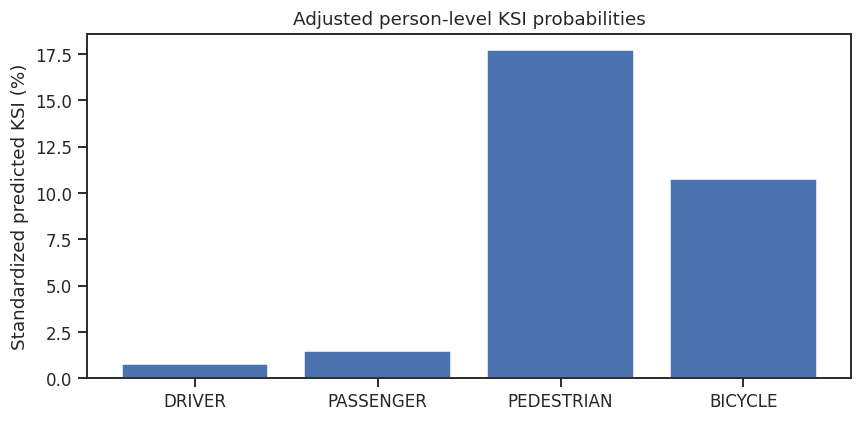

In [61]:
# VALIDATION 4 — ADJUSTED PROBABILITIES

def standardized_probability(
    fit, base, column, levels, chunk=100000
):
    rows = []

    for level in levels:
        if level not in set(base[column].astype(str)):
            continue

        total = 0.0
        count = 0

        for start in range(0, len(base), chunk):
            frame = base.iloc[start:start + chunk].copy()
            frame[column] = level

            pr = np.asarray(fit.predict(frame))

            total += pr.sum()
            count += len(pr)

        rows.append({
            "factor": column,
            "level": level,
            "adjusted_ksi_pct": 100 * total / count,
            "standardization_n": count
        })

    return rows


pred_rows = []

pred_rows += standardized_probability(
    person_fit,
    person_model,
    "person_type",
    ["DRIVER", "PASSENGER", "PEDESTRIAN", "BICYCLE"]
)

pred_rows += standardized_probability(
    person_fit,
    person_model,
    "speed_cat",
    ["5-20", "25", "30", "35", "40+"]
)

pred_table = pd.DataFrame(pred_rows)

display(pred_table.round(3))

pred_table.to_csv(
    OUT / "validation_adjusted_probabilities.csv",
    index=False
)

sub = pred_table.loc[
    pred_table.factor == "person_type"
]

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    sub.level,
    sub.adjusted_ksi_pct
)

ax.set(
    ylabel="Standardized predicted KSI (%)",
    title="Adjusted person-level KSI probabilities"
)

fig.tight_layout()

fig.savefig(
    OUT / "validation_adjusted_person_probabilities.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

Eligible beats: 269
Spearman correlation: 0.546
Top-15 overlap: 4 of 15


,n_2018-21,n_2022-25,ksi_2018-21,ksi_2022-25,rate_pct_2018-21,rate_pct_2022-25,rate_ratio_late_vs_early,total_ksi,top15_both
beat,,,,,,,,,
1132,1300.0,1010.0,50.0,40.0,3.846,3.960,1.030,90.0,True
213,1156.0,1004.0,39.0,34.0,3.374,3.386,1.004,73.0,True
523,1178.0,1112.0,44.0,34.0,3.735,3.058,0.819,78.0,True
1011,1286.0,1052.0,45.0,30.0,3.499,2.852,0.815,75.0,True


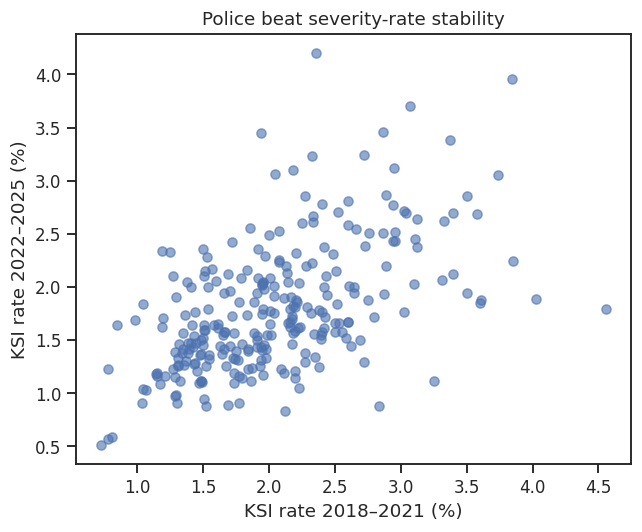

In [60]:
# VALIDATION 5 — HOTSPOT STABILITY

b = crashes.dropna(
    subset=["beat", "ksi", "year"]
).copy()

b["period"] = np.where(
    b.year <= 2021,
    "2018-21",
    "2022-25"
)

hot = (
    b.groupby(["beat", "period"])["ksi"]
    .agg(n="size", ksi="sum")
    .reset_index()
)

hot["rate_pct"] = 100 * hot.ksi / hot.n

p = hot.pivot(
    index="beat",
    columns="period",
    values=["n", "ksi", "rate_pct"]
)

p.columns = [
    f"{a}_{period}"
    for a, period in p.columns
]

p = p.dropna().copy()

p = p.loc[
    (p["n_2018-21"] >= 500) &
    (p["n_2022-25"] >= 500)
]

p["rate_ratio_late_vs_early"] = (
    p["rate_pct_2022-25"] /
    p["rate_pct_2018-21"].replace(0, np.nan)
)

p["total_ksi"] = (
    p["ksi_2018-21"] + p["ksi_2022-25"]
)

p = p.sort_values("total_ksi", ascending=False)

print("Eligible beats:", len(p))

correlation = spearmanr(
    p["rate_pct_2018-21"],
    p["rate_pct_2022-25"]
)

print(
    "Spearman correlation:",
    round(correlation.statistic, 3)
)

top_early = set(
    p.nlargest(15, "rate_pct_2018-21").index
)

top_late = set(
    p.nlargest(15, "rate_pct_2022-25").index
)

overlap = top_early & top_late

print("Top-15 overlap:", len(overlap), "of 15")

p["top15_both"] = p.index.isin(overlap)

display(
    p.loc[p.top15_both]
    .sort_values("rate_pct_2022-25", ascending=False)
    .round(3)
)

p.to_csv(
    OUT / "validation_hotspot_stability.csv"
)

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    p["rate_pct_2018-21"],
    p["rate_pct_2022-25"],
    alpha=0.6
)

ax.set(
    xlabel="KSI rate 2018–2021 (%)",
    ylabel="KSI rate 2022–2025 (%)",
    title="Police beat severity-rate stability"
)

fig.tight_layout()

fig.savefig(
    OUT / "validation_hotspot_stability.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

In [62]:
# FINAL REPORT AUDIT — YEAR AND MONTH COVERAGE

audit = crashes.copy()
audit["date_check"] = pd.to_datetime(audit["date"])
audit["audit_year"] = audit["date_check"].dt.year
audit["audit_month"] = audit["date_check"].dt.month

coverage = (
    audit.groupby(["audit_year", "audit_month"])
    .agg(
        crashes=("CRASH_RECORD_ID", "size"),
        known_ksi=("ksi", "count"),
        ksi_crashes=("ksi", "sum")
    )
    .reset_index()
)

coverage["ksi_rate_pct"] = (
    100 * coverage["ksi_crashes"] / coverage["known_ksi"]
)

monthly_counts = coverage.pivot(
    index="audit_month",
    columns="audit_year",
    values="crashes"
)

print("Monthly crash counts:")
display(monthly_counts)

print("Last crash date:", audit["date_check"].max())

annual_check = (
    audit.groupby("audit_year")
    .agg(
        total_crashes=("CRASH_RECORD_ID", "size"),
        known_ksi=("ksi", "count"),
        ksi_crashes=("ksi", "sum")
    )
)

annual_check["ksi_rate_pct"] = (
    100 * annual_check["ksi_crashes"] /
    annual_check["known_ksi"]
)

display(annual_check.round(3))

Monthly crash counts:


audit_year,2018,2019,2020,2021,2022,2023,2024,2025
audit_month,,,,,,,,
1,9532,9116,8685,7072,8195,8105,8234,8221
2,8730,8625,9019,8399,7963,8099,7800,7764
3,9319,9748,6672,7679,8552,8895,8927,8739
4,9648,9446,4431,8169,8533,9012,9254,8919
5,10714,10709,6548,9651,9825,10142,10742,10103
6,10602,10706,7680,10335,9602,9590,10136,10102
7,10367,10662,9042,10015,9263,9528,9606,9828
8,10212,9941,9161,9989,9233,9777,9924,10192
9,9931,9815,8286,9897,9602,9616,9816,9043


Last crash date: 2025-12-31 23:52:00


,total_crashes,known_ksi,ksi_crashes,ksi_rate_pct
audit_year,,,,
2018,118952,118728,2255.0,1.899
2019,117764,117499,2113.0,1.798
2020,92096,91860,2022.0,2.201
2021,108767,108519,2187.0,2.015
2022,108413,108119,2093.0,1.936
2023,110754,110493,2035.0,1.842
2024,112056,111805,1739.0,1.555
2025,109117,108902,1573.0,1.444


Design matrix verified successfully.

ADJUSTED KSI PROBABILITIES WITH 95% CI


,factor,level,adjusted_pct,ci_low,ci_high
0,person_type,DRIVER,0.811,0.795,0.831
1,person_type,PASSENGER,1.494,1.433,1.556
2,person_type,PEDESTRIAN,17.781,17.284,18.334
3,person_type,BICYCLE,10.817,10.277,11.363
4,speed_cat,5-20,0.764,0.712,0.813
5,speed_cat,25,1.123,1.054,1.212
6,speed_cat,30,1.300,1.275,1.328
7,speed_cat,35,1.756,1.670,1.840
8,speed_cat,40+,2.579,2.364,2.820


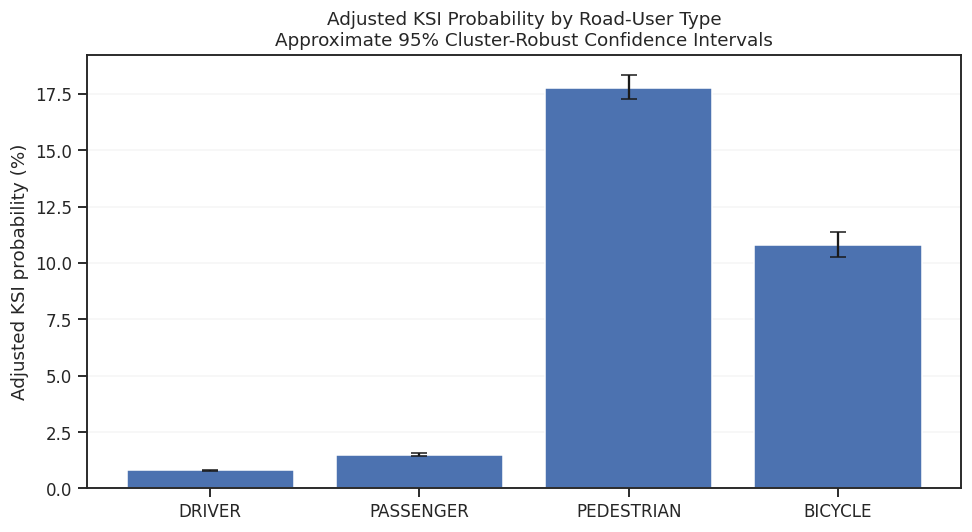


Completed successfully.
Results saved to: /content/drive/MyDrive/ChicagoTrafficData/report_outputs


In [64]:
# FINAL EXTENSION 1 — ADJUSTED PROBABILITIES WITH 95% CI

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import patsy

from pathlib import Path
from scipy.special import expit
from statsmodels.stats.sandwich_covariance import cov_cluster
from IPython.display import display

OUT = Path("/content/drive/MyDrive/ChicagoTrafficData/report_outputs")
OUT.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(504)

# --------------------------------------------------
# 1. Use existing fitted logistic regression
# --------------------------------------------------

beta = person_fit.params.to_numpy()
model_columns = list(person_fit.params.index)

# Sample observations for standardized predictions
base = person_model.sample(
    n=min(15000, len(person_model)),
    random_state=504
).copy()

# Recover Patsy design information, if available.
# Otherwise reconstruct it from the existing formula.
design_info = getattr(
    person_fit.model.data,
    "design_info",
    None
)

if design_info is None:

    # Use a small sample, but preserve all categorical
    # levels present in the fitted model.
    reference = base.copy()

    for col in person_model.select_dtypes(
        include=["object", "category", "string"]
    ).columns:

        if col not in reference.columns:
            continue

        if isinstance(
            person_model[col].dtype,
            pd.CategoricalDtype
        ):
            reference[col] = pd.Categorical(
                reference[col],
                categories=person_model[col].cat.categories
            )

    _, X_reference = patsy.dmatrices(
        person_formula,
        data=reference,
        return_type="dataframe"
    )

    design_info = X_reference.design_info

# --------------------------------------------------
# 2. Verify exact coefficient alignment
# --------------------------------------------------

design_columns = list(design_info.column_names)

if set(design_columns) != set(model_columns):
    raise ValueError(
        "Reconstructed design columns do not match "
        "the fitted model.\n"
        f"Missing: {set(model_columns) - set(design_columns)}\n"
        f"Extra: {set(design_columns) - set(model_columns)}"
    )

print("Design matrix verified successfully.")

# --------------------------------------------------
# 3. Compute crash-clustered covariance
# --------------------------------------------------

fit_idx = person_fit.model.data.row_labels

groups = people.loc[
    fit_idx, "CRASH_RECORD_ID"
].astype(str).to_numpy()

V = cov_cluster(person_fit, groups)

# Ensure covariance is numerically symmetric
V = (V + V.T) / 2

# Stabilize covariance for simulations
eigenvalues, eigenvectors = np.linalg.eigh(V)

V_psd = (
    eigenvectors
    * np.maximum(eigenvalues, 0)
) @ eigenvectors.T

# Draw coefficients from approximate sampling distribution
draws = rng.multivariate_normal(
    beta,
    V_psd,
    size=300,
    method="svd"
)

# --------------------------------------------------
# 4. Standardized probabilities and intervals
# --------------------------------------------------

factors = {
    "person_type": [
        "DRIVER",
        "PASSENGER",
        "PEDESTRIAN",
        "BICYCLE"
    ],
    "speed_cat": [
        "5-20",
        "25",
        "30",
        "35",
        "40+"
    ]
}

results = []

for factor, levels in factors.items():

    for level in levels:

        frame = base.copy()
        frame[factor] = level

        X = patsy.build_design_matrices(
            [design_info],
            frame,
            return_type="dataframe"
        )[0]

        # Match fitted coefficient order exactly
        X = X[model_columns].to_numpy()

        # Point estimate
        point = 100 * expit(X @ beta).mean()

        # Approximate uncertainty interval
        simulated = []

        for draw in draws:
            simulated.append(
                100 * expit(X @ draw).mean()
            )

        ci_low, ci_high = np.percentile(
            simulated,
            [2.5, 97.5]
        )

        results.append({
            "factor": factor,
            "level": level,
            "adjusted_pct": point,
            "ci_low": ci_low,
            "ci_high": ci_high
        })

prob_ci = pd.DataFrame(results)

print("\nADJUSTED KSI PROBABILITIES WITH 95% CI")
display(prob_ci.round(3))

# --------------------------------------------------
# 5. Save results
# --------------------------------------------------

prob_ci.to_csv(
    OUT / "final_adjusted_probability_ci.csv",
    index=False
)

# --------------------------------------------------
# 6. Plot adjusted probabilities by person type
# --------------------------------------------------

sub = prob_ci.loc[
    prob_ci["factor"] == "person_type"
].copy()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    sub["level"],
    sub["adjusted_pct"],
    yerr=[
        sub["adjusted_pct"] - sub["ci_low"],
        sub["ci_high"] - sub["adjusted_pct"]
    ],
    capsize=5
)

ax.set(
    ylabel="Adjusted KSI probability (%)",
    title=(
        "Adjusted KSI Probability by Road-User Type\n"
        "Approximate 95% Cluster-Robust Confidence Intervals"
    )
)

ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    OUT / "final_adjusted_probability_ci.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nCompleted successfully.")
print("Results saved to:", OUT)

Highest observed KSI-rate combinations (n >= 100):


,person_type,speed_cat,lighting_group,n,ksi,ksi_pct,ci_low,ci_high
14,PEDESTRIAN,30,Darkness,5786,1217.0,21.034,20.003,22.103
16,PEDESTRIAN,35,Darkness,509,107.0,21.022,17.706,24.772
17,PEDESTRIAN,35,Daylight,866,177.0,20.439,17.886,23.252
12,PEDESTRIAN,25,Darkness,489,84.0,17.178,14.094,20.774
15,PEDESTRIAN,30,Daylight,10910,1732.0,15.875,15.202,16.573
10,PEDESTRIAN,5-20,Darkness,651,101.0,15.515,12.937,18.497
2,BICYCLE,25,Darkness,188,28.0,14.894,10.510,20.683
6,BICYCLE,35,Darkness,229,32.0,13.974,10.075,19.061
13,PEDESTRIAN,25,Daylight,1007,136.0,13.505,11.533,15.756
11,PEDESTRIAN,5-20,Daylight,1924,243.0,12.630,11.220,14.189


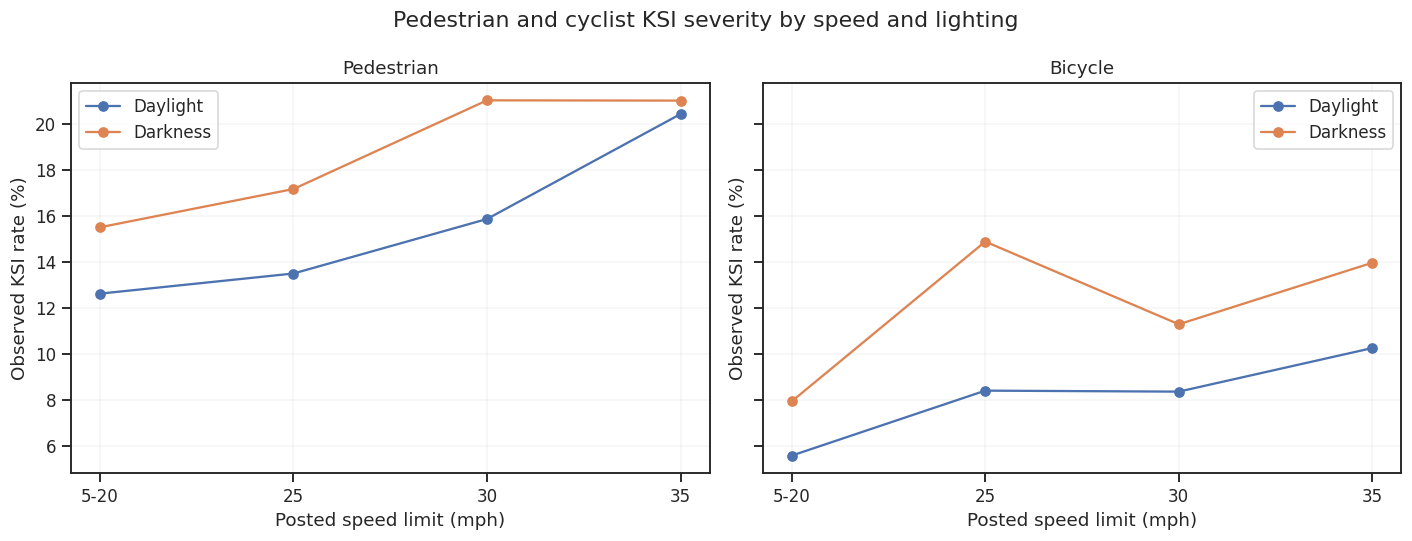

In [65]:
# FINAL EXTENSION 2 — HIGH-SEVERITY COMBINATIONS

from statsmodels.stats.proportion import proportion_confint

vr = people.loc[
    people["person_type"].isin(["PEDESTRIAN", "BICYCLE"])
].copy()

lighting = vr["LIGHTING_CONDITION"].astype("string").str.upper()

vr["lighting_group"] = np.select(
    [
        lighting.eq("DAYLIGHT").fillna(False),
        lighting.str.contains("DARKNESS", na=False).fillna(False)
    ],
    ["Daylight", "Darkness"],
    default="Other/unknown"
)

vr = vr.loc[
    vr["lighting_group"].isin(["Daylight", "Darkness"])
].dropna(subset=["ksi", "speed_cat"])

summary = (
    vr.groupby(
        ["person_type", "speed_cat", "lighting_group"],
        observed=True
    )["ksi"]
    .agg(n="count", ksi="sum")
    .reset_index()
)

summary["ksi_pct"] = 100 * summary["ksi"] / summary["n"]

low, high = proportion_confint(
    summary["ksi"],
    summary["n"],
    alpha=0.05,
    method="wilson"
)

summary["ci_low"] = low * 100
summary["ci_high"] = high * 100

# Minimum sample threshold for interpretable comparisons.
stable = summary.loc[summary["n"] >= 100].copy()

stable = stable.sort_values(
    "ksi_pct", ascending=False
)

print("Highest observed KSI-rate combinations (n >= 100):")

display(stable.head(15).round(3))

summary.to_csv(
    OUT / "final_vulnerable_subgroups_all.csv",
    index=False
)

stable.to_csv(
    OUT / "final_vulnerable_subgroups_stable.csv",
    index=False
)

# Visual comparison across speed categories.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

speed_order = ["5-20", "25", "30", "35", "40+"]

for ax, person in zip(axes, ["PEDESTRIAN", "BICYCLE"]):
    part = stable.loc[stable["person_type"] == person]

    for light in ["Daylight", "Darkness"]:
        s = part.loc[
            part["lighting_group"] == light
        ].set_index("speed_cat")

        s = s.reindex(speed_order)

        ax.plot(
            speed_order,
            s["ksi_pct"],
            marker="o",
            label=light
        )

    ax.set(
        title=person.title(),
        xlabel="Posted speed limit (mph)",
        ylabel="Observed KSI rate (%)"
    )
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle(
    "Pedestrian and cyclist KSI severity by speed and lighting"
)
plt.tight_layout()

plt.savefig(
    OUT / "final_vulnerable_conditions.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

Model inclusion by year:


,year,total,included,retention_pct
0,2018,265716,187329,70.50
1,2019,264003,187759,71.12
2,2020,199994,138917,69.46
3,2021,233799,157555,67.39
4,2022,233845,157458,67.33
5,2023,245190,162913,66.44
6,2024,246702,168389,68.26
7,2025,238402,163578,68.61



Model inclusion by person type and injury severity:


,person_type,ksi_group,total,included,retention_pct
0,BICYCLE,KSI,1389,1303,93.81
1,BICYCLE,Non-KSI,14129,11604,82.13
2,BICYCLE,Unknown,2,0,0.00
3,DRIVER,KSI,9223,8610,93.35
4,DRIVER,Non-KSI,1485667,1048929,70.60
5,Other,KSI,63,51,80.95
6,Other,Non-KSI,1714,721,42.07
7,Other,Unknown,210,0,0.00
8,PASSENGER,KSI,4044,3310,81.85
9,PASSENGER,Non-KSI,386642,227843,58.93



Missingness by predictor:


,variable,missing_n,missing_pct
1,age_cat,556414,28.86
2,sex,211958,11.00
4,LIGHTING_CONDITION,72838,3.78
3,speed_cat,8956,0.46
0,person_type,0,0.00



KSI outcome by model inclusion:


,included,known_outcomes,ksi_cases,ksi_rate,ksi_pct
0,False,603197,1797.0,0.003,0.298
1,True,1323898,17065.0,0.013,1.289


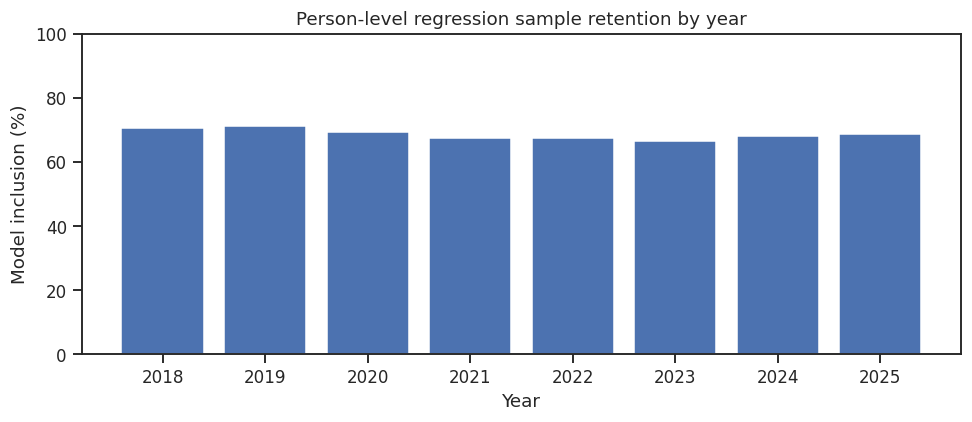

Completed missing-data audit.


In [66]:
# FINAL EXTENSION 3 — MISSING-DATA BIAS AUDIT

# Map crash year onto person records without a large merge.
year_lookup = (
    crashes[["CRASH_RECORD_ID", "year"]]
    .drop_duplicates("CRASH_RECORD_ID")
    .set_index("CRASH_RECORD_ID")["year"]
)

audit = pd.DataFrame(index=people.index)

audit["year"] = people["CRASH_RECORD_ID"].map(year_lookup)
audit["person_type"] = people["person_type"]
audit["ksi"] = people["ksi"]

audit["included"] = people.index.isin(person_model.index)

audit["ksi_group"] = np.select(
    [
        audit["ksi"].eq(1),
        audit["ksi"].eq(0)
    ],
    ["KSI", "Non-KSI"],
    default="Unknown"
)

# Overall inclusion by year.
year_audit = (
    audit.groupby("year")
    .agg(
        total=("included", "size"),
        included=("included", "sum")
    )
    .reset_index()
)

year_audit["retention_pct"] = (
    100 * year_audit["included"] / year_audit["total"]
)

print("Model inclusion by year:")
display(year_audit.round(2))

# Inclusion by person type and injury severity.
group_audit = (
    audit.groupby(
        ["person_type", "ksi_group"],
        observed=True
    )["included"]
    .agg(total="size", included="sum")
    .reset_index()
)

group_audit["retention_pct"] = (
    100 * group_audit["included"] / group_audit["total"]
)

print("\nModel inclusion by person type and injury severity:")
display(
    group_audit.sort_values(
        ["person_type", "ksi_group"]
    ).round(2)
)

# Missingness of individual model predictors.
predictors = [
    "person_type", "age_cat", "sex",
    "speed_cat", "LIGHTING_CONDITION"
]

missing_table = pd.DataFrame({
    "variable": predictors,
    "missing_n": [
        int(people[col].isna().sum()) for col in predictors
    ],
    "missing_pct": [
        100 * people[col].isna().mean()
        for col in predictors
    ]
})

print("\nMissingness by predictor:")
display(
    missing_table.sort_values(
        "missing_pct", ascending=False
    ).round(2)
)

# Compare outcome prevalence in included and excluded records.
outcome_audit = (
    audit.groupby("included")["ksi"]
    .agg(
        known_outcomes="count",
        ksi_cases="sum",
        ksi_rate="mean"
    )
    .reset_index()
)

outcome_audit["ksi_pct"] = (
    100 * outcome_audit["ksi_rate"]
)

print("\nKSI outcome by model inclusion:")
display(outcome_audit.round(3))

year_audit.to_csv(
    OUT / "final_missingness_by_year.csv",
    index=False
)

group_audit.to_csv(
    OUT / "final_missingness_by_group.csv",
    index=False
)

missing_table.to_csv(
    OUT / "final_missingness_by_variable.csv",
    index=False
)

outcome_audit.to_csv(
    OUT / "final_missingness_outcome.csv",
    index=False
)

# Visualize retention by year.
fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    year_audit["year"].astype(str),
    year_audit["retention_pct"]
)

ax.set(
    xlabel="Year",
    ylabel="Model inclusion (%)",
    title="Person-level regression sample retention by year",
    ylim=(0, 100)
)

plt.tight_layout()

plt.savefig(
    OUT / "final_missingness_by_year.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Completed missing-data audit.")

Original complete-case sample: 1323898
Expanded sample: 1927095
Additional records: 603197
Expanded sample KSI rate: 0.979 %

ODDS RATIO SENSITIVITY COMPARISON


,original_OR,expanded_OR,relative_change_pct
LIGHTING_CONDITION: DARKNESS,1.402,1.429,1.942
"LIGHTING_CONDITION: DARKNESS, LIGHTED ROAD",1.849,1.871,1.155
LIGHTING_CONDITION: DAWN,1.571,1.566,-0.296
LIGHTING_CONDITION: DUSK,1.127,1.142,1.374
LIGHTING_CONDITION: Missing/Unknown,NaN,0.461,NaN
age_cat: 0-15,0.735,0.713,-3.110
age_cat: 16-24,1.036,1.027,-0.836
age_cat: 45-64,1.116,1.113,-0.255
age_cat: 65+,1.367,1.365,-0.149
age_cat: Missing/Unknown,NaN,0.290,NaN



KEY ROAD-USER EFFECTS


,original_OR,expanded_OR,relative_change_pct
person_type: BICYCLE,15.069,15.521,2.998
person_type: PEDESTRIAN,27.139,29.464,8.565


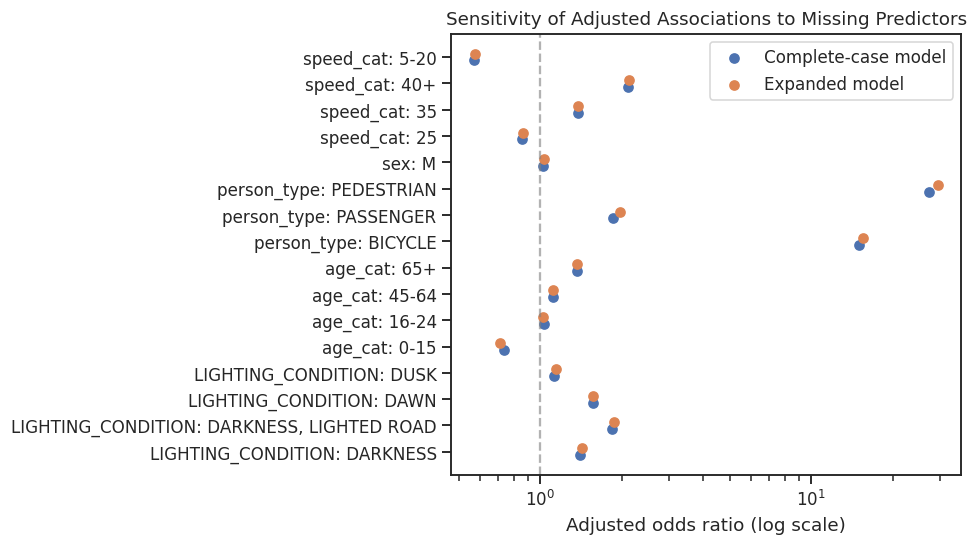


Sensitivity analysis completed.
Results saved to: /content/drive/MyDrive/ChicagoTrafficData/report_outputs


In [67]:
# FINAL SENSITIVITY ANALYSIS
# Missing/Unknown categories versus complete-case regression

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

OUT = Path("/content/drive/MyDrive/ChicagoTrafficData/report_outputs")
OUT.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------
# 1. Construct expanded person-level sample
# ---------------------------------------------

predictors = [
    "person_type",
    "age_cat",
    "sex",
    "speed_cat",
    "LIGHTING_CONDITION"
]

expanded = people[["ksi", "CRASH_RECORD_ID"] + predictors].copy()

# Only remove records without a known KSI outcome
expanded = expanded.dropna(subset=["ksi", "CRASH_RECORD_ID"])

for col in predictors:
    expanded[col] = (
        expanded[col]
        .astype("object")
        .fillna("Missing/Unknown")
        .astype(str)
    )

# Match the original rare-category handling
for col in ["person_type", "LIGHTING_CONDITION"]:
    counts = expanded[col].value_counts()
    rare = counts.index[
        (counts < 3000) &
        (counts.index != "Missing/Unknown")
    ]
    expanded[col] = expanded[col].replace(
        list(rare), "Other"
    )

# Explicit original reference levels
refs = {
    "person_type": "DRIVER",
    "age_cat": "25-44",
    "sex": "F",
    "speed_cat": "30",
    "LIGHTING_CONDITION": person_refs["LIGHTING_CONDITION"]
}

for col, ref in refs.items():
    assert ref in expanded[col].unique(), (
        f"Missing reference: {col}={ref}"
    )

# ---------------------------------------------
# 2. Fit expanded regression
# ---------------------------------------------

expanded_formula = treatment_formula("ksi", refs)

expanded_fit = smf.glm(
    expanded_formula,
    data=expanded,
    family=sm.families.Binomial()
).fit()

print("Original complete-case sample:", len(person_model))
print("Expanded sample:", len(expanded))
print(
    "Additional records:",
    len(expanded) - len(person_model)
)

print(
    "Expanded sample KSI rate:",
    round(100 * expanded["ksi"].mean(), 3), "%"
)

# ---------------------------------------------
# 3. Compare original and expanded odds ratios
# ---------------------------------------------

def extract_or(fit):
    result = pd.DataFrame({
        "OR": np.exp(fit.params),
        "CI_low": np.exp(fit.conf_int()[0]),
        "CI_high": np.exp(fit.conf_int()[1])
    })

    result.index = clean_terms(result.index)
    return result.drop(
        index="Intercept", errors="ignore"
    )

original_or = extract_or(person_fit)
expanded_or = extract_or(expanded_fit)

comparison = original_or[["OR"]].rename(
    columns={"OR": "original_OR"}
).join(
    expanded_or[["OR"]].rename(
        columns={"OR": "expanded_OR"}
    ),
    how="outer"
)

comparison["relative_change_pct"] = (
    100 *
    (comparison["expanded_OR"] /
     comparison["original_OR"] - 1)
)

print("\nODDS RATIO SENSITIVITY COMPARISON")
display(comparison.round(3))

# ---------------------------------------------
# 4. Key road-user comparisons
# ---------------------------------------------

key_terms = [
    "person_type: PEDESTRIAN",
    "person_type: BICYCLE"
]

print("\nKEY ROAD-USER EFFECTS")
display(
    comparison.loc[
        comparison.index.intersection(key_terms)
    ].round(3)
)

# ---------------------------------------------
# 5. Plot comparable odds ratios
# ---------------------------------------------

plot_data = comparison.dropna(
    subset=["original_OR", "expanded_OR"]
).copy()

plot_data = plot_data.loc[
    ~plot_data.index.str.contains(
        "Missing/Unknown|UNKNOWN|Other",
        case=False,
        regex=True
    )
]

fig, ax = plt.subplots(figsize=(9, max(5, len(plot_data) * 0.32)))

y = np.arange(len(plot_data))

ax.scatter(
    plot_data["original_OR"],
    y - 0.13,
    label="Complete-case model"
)

ax.scatter(
    plot_data["expanded_OR"],
    y + 0.13,
    label="Expanded model"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_data.index)
ax.set_xscale("log")
ax.set_xlabel("Adjusted odds ratio (log scale)")
ax.set_title(
    "Sensitivity of Adjusted Associations to Missing Predictors"
)
ax.axvline(1, linestyle="--", color="gray", alpha=0.6)
ax.legend()

plt.tight_layout()

plt.savefig(
    OUT / "final_missing_category_sensitivity.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ---------------------------------------------
# 6. Save results
# ---------------------------------------------

comparison.to_csv(
    OUT / "final_missing_category_sensitivity.csv"
)

print("\nSensitivity analysis completed.")
print("Results saved to:", OUT)